# Phase 3: Advanced Object Tracking Mastery
Welcome to Phase 3 of the Team Chati Pati Computer Vision Bootcamp.
Detecting objects frame-by-frame is not enough for real-world video analytics. We need to assign a unique ID to each object and track its trajectory over time, even when the detector fails or objects overlap.

**Roadmap Overview:**
* **Day 16 & 17:** Centroid & IoU Tracking (The greedy approach and its flaws).
* **Day 18:** The Assignment Problem (Hungarian Algorithm).
* **Day 19:** Predicting the Future (Kalman Filter).
* **Day 20:** Object-Oriented Track Lifecycle (Birth, Memory, Death).
* **Day 21:** End-to-End Pipeline (YOLOv8 + Custom SORT Tracker).
* **Day 22 & 23:** Tracking Comparison (SORT vs. ByteTrack) & Failure Analysis.

**Part II — Ultralytics Tracking Toolbox & Modern Trackers (new):**
* **Day 24:** The `model.track()` API, `persist`, `stream`, and the `Results` object.
* **Day 25:** The six built-in trackers (BoT-SORT, ByteTrack, OC-SORT, Deep OC-SORT, FastTracker, TrackTrack) and how to choose.
* **Day 26–31:** One deep dive per tracker, each with a from-scratch concept demo.
* **Day 32:** Customising tracker YAML files, presets and parameter sweeps.
* **Day 33–34:** Track trails and multithreaded tracking.
* **Day 35:** Classic OpenCV single-object trackers (BOOSTING, MIL, KCF, CSRT, TLD, MEDIANFLOW, GOTURN, MOSSE).
* **Day 36:** Evaluation metrics (MOTA, IDF1, HOTA) and a mini evaluator.
* **Day 37:** Cheat-sheet, troubleshooting guide and exercises.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy.spatial import distance
from scipy.optimize import linear_sum_assignment
from filterpy.kalman import KalmanFilter
from ultralytics import YOLO

plt.rcParams['figure.figsize'] = (10, 6)

def show_frames(frames, titles, cols=3):
    rows = (len(frames) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    for i, ax in enumerate(axes.flatten()):
        if i < len(frames):
            ax.imshow(cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB))
            ax.set_title(titles[i])
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# Helper from Phase 2
def calculate_iou(boxA, boxB):
    xA, yA = max(boxA[0], boxB[0]), max(boxA[1], boxB[1])
    xB, yB = min(boxA[2], boxB[2]), min(boxA[3], boxB[3])
    interArea = max(0, xB - xA) * max(0, yB - yA)
    boxAArea = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxBArea = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])
    union = boxAArea + boxBArea - interArea
    return interArea / float(union) if union > 0 else 0.0

## Day 16 & 17 — Centroid & IoU Tracking
**Topics:** Distance Matching, IoU Matrix, Greedy Matching, ID Switches

### 1. Centroid Distance Tracking
The simplest way to track is to calculate the center point (centroid) of bounding boxes in Frame $T$ and Frame $T+1$. We assign the ID of the closest past centroid to the new centroid using Euclidean Distance.
* **Flaw:** If a fast-moving object passes a slow-moving one, their distances might get mixed up.

### 2. IoU Tracking & Greedy Matching
Instead of centroids, we use the Intersection over Union (IoU) of boxes. 
* **The Matrix:** We build a cost matrix comparing every Detection to every existing Track.
* **Greedy Approach:** Pick the highest IoU, assign it, move to the next. 
* **The ID Switch Problem:** Greedy matching fails during occlusions. If Object A crosses Object B, greedy matching will steal the ID of whichever object randomly gets evaluated first, leading to an **ID Switch**.

In [2]:
# Synthetic Data: Generating two overlapping tracks
# Detections: [x1, y1, x2, y2]
frame1_tracks = [[10, 10, 50, 50], [100, 100, 140, 140]] # IDs: 0, 1
frame2_detections = [[110, 110, 150, 150], [20, 20, 60, 60]] # Shuffled order!

def compute_iou_matrix(tracks, detections):
    matrix = np.zeros((len(tracks), len(detections)))
    for t, trk in enumerate(tracks):
        for d, det in enumerate(detections):
            matrix[t, d] = calculate_iou(trk, det)
    return matrix

iou_matrix = compute_iou_matrix(frame1_tracks, frame2_detections)
print("IoU Matrix (Tracks vs Detections):\n", np.round(iou_matrix, 2))

# Greedy Matching
print("\n--- GREEDY MATCHING ---")
matched_tracks = set()
matched_dets = set()

for t in range(len(frame1_tracks)):
    best_iou = 0
    best_d = -1
    for d in range(len(frame2_detections)):
        if d not in matched_dets and iou_matrix[t, d] > best_iou:
            best_iou = iou_matrix[t, d]
            best_d = d
            
    if best_iou > 0.3: # Threshold
        print(f"Track {t} uniquely matched to Detection {best_d} (IoU: {best_iou:.2f})")
        matched_tracks.add(t)
        matched_dets.add(best_d)

IoU Matrix (Tracks vs Detections):
 [[0.   0.39]
 [0.39 0.  ]]

--- GREEDY MATCHING ---
Track 0 uniquely matched to Detection 1 (IoU: 0.39)
Track 1 uniquely matched to Detection 0 (IoU: 0.39)


## Day 18 — The Assignment Problem & Hungarian Algorithm
**Topics:** Global Optimization, Cost Matrix, `linear_sum_assignment`

### Why Greedy Fails
Imagine 3 workers and 3 tasks. Worker A can do Task 1 for $5 and Task 2 for $6. A greedy algorithm assigns Worker A to Task 1 instantly. But what if Worker B can *only* do Task 1? Now Worker B is unemployed! A global view shows Worker A should take Task 2 so everyone works.

### The Hungarian Algorithm (Kuhn-Munkres)
This algorithm finds the **global mathematical minimum cost** for assigning $N$ tracks to $M$ detections in $O(n^3)$ time.
* Since Hungarian minimizes cost, and higher IoU is better, our cost matrix becomes: $Cost = 1 - IoU$.

In [3]:
print("--- HUNGARIAN ALGORITHM MATCHING ---")
# Let's create a complex synthetic cost matrix (3 Tracks vs 3 Detections)
# Cost = 1.0 - IoU (Lower is better)
cost_matrix = np.array([
    [0.9, 0.1, 0.8],  # Track 0 costs
    [0.8, 0.2, 0.9],  # Track 1 costs (Greedy would pick Det 1, stealing it from Track 0!)
    [0.1, 0.9, 0.9]   # Track 2 costs
])

# 1. Greedy approach will fail here
print("Greedy would do: T0->D1, T1->Missed(D1 taken), T2->D0")

# 2. Hungarian Global Optimization
row_ind, col_ind = linear_sum_assignment(cost_matrix)

print("\nHungarian Solution:")
for t, d in zip(row_ind, col_ind):
    print(f"Track {t} -> Detection {d} (Cost: {cost_matrix[t, d]:.2f})")
print("Notice how Hungarian forced Track 1 to take Det 1, and Track 0 to take Det 2 to minimize GLOBAL cost!")

--- HUNGARIAN ALGORITHM MATCHING ---
Greedy would do: T0->D1, T1->Missed(D1 taken), T2->D0

Hungarian Solution:
Track 0 -> Detection 1 (Cost: 0.10)
Track 1 -> Detection 2 (Cost: 0.90)
Track 2 -> Detection 0 (Cost: 0.10)
Notice how Hungarian forced Track 1 to take Det 1, and Track 0 to take Det 2 to minimize GLOBAL cost!


## Day 19 — Predicting the Future (Kalman Filter)
**Topics:** State vs. Measurement, Prediction, Update, Tracking Through Occlusion

If a person walks behind a tree, YOLO detects nothing (Measurement = `None`). Does the person cease to exist? No! Physics dictates they are still moving.
* **State Vector (Internal Reality):** $[x, y, v_x, v_y]$ (Position and Velocity).
* **Measurement Vector (Sensor Reality):** $[x, y]$ (What YOLO sees).
* **Prediction Step:** Uses velocity to guess where the box is *now* based on the previous frame.
* **Update Step:** YOLO provides a new measurement. The Kalman Filter computes the "Kalman Gain" to balance trust between its Physics Prediction and YOLO's Measurement (handling sensor noise).

In [4]:
# Simulating an object moving right at constant speed, but YOLO misses frame 3 and 4!
measurements = [[10, 10], [20, 10], [30, 10], None, None, [60, 10], [70, 10]]

# Initialize Kalman Filter (4 State Variables: x, y, dx, dy), (2 Measurements: x, y)
kf = KalmanFilter(dim_x=4, dim_z=2)
kf.x = np.array([0., 10., 10., 0.]) # Initial State Guess: x=0, y=10, vx=10, vy=0
kf.F = np.array([[1,0,1,0], [0,1,0,1], [0,0,1,0], [0,0,0,1]]) # State Transition (x = x + vx*dt)
kf.H = np.array([[1,0,0,0], [0,1,0,0]]) # Measurement Function
kf.P *= 10. # Covariance (Uncertainty matrix)
kf.R = np.eye(2) * 5 # Measurement Noise (How much we doubt YOLO)
kf.Q = np.eye(4) * 0.1 # Process Noise (How much we doubt physics)

predictions = []
for z in measurements:
    kf.predict() # Step 1: Physics Prediction
    if z is not None:
        kf.update(z) # Step 2: Sensor Update
    predictions.append(kf.x[:2].copy()) # Save current [x, y] state

print("--- KALMAN FILTER OCCLUSION TEST ---")
for i, (meas, pred) in enumerate(zip(measurements, predictions)):
    meas_str = str(meas) if meas else "MISSING (Occluded)"
    print(f"Frame {i}: YOLO = {meas_str:>18} | Kalman Output = [{pred[0]:.1f}, {pred[1]:.1f}]")
print("SUCCESS: Kalman Filter successfully predicted movement during occlusion!")

--- KALMAN FILTER OCCLUSION TEST ---
Frame 0: YOLO =           [10, 10] | Kalman Output = [10.0, 10.0]
Frame 1: YOLO =           [20, 10] | Kalman Output = [20.0, 10.0]
Frame 2: YOLO =           [30, 10] | Kalman Output = [30.0, 10.0]
Frame 3: YOLO = MISSING (Occluded) | Kalman Output = [40.0, 10.0]
Frame 4: YOLO = MISSING (Occluded) | Kalman Output = [50.0, 10.0]
Frame 5: YOLO =           [60, 10] | Kalman Output = [60.0, 10.0]
Frame 6: YOLO =           [70, 10] | Kalman Output = [70.0, 10.0]
SUCCESS: Kalman Filter successfully predicted movement during occlusion!


## Day 20 & 21 — The `Track` Lifecycle & Full Pipeline
**Topics:** SORT Architecture, Track Birth/Death, Video Integration

We now integrate everything into a simplified version of **SORT** (Simple Online and Realtime Tracking).
1. **Track Lifecycle:** A track starts as `Tentative`. If updated 3 times, it becomes `Confirmed`. If YOLO misses it for `max_age` (e.g., 30 frames), it is `Deleted`.
2. **The Pipeline:** `Frame -> YOLO -> Kalman Predict -> Hungarian IoU Match -> Kalman Update`.

Let's generate a synthetic video with moving, overlapping rectangles to prove our tracker handles ID switches!

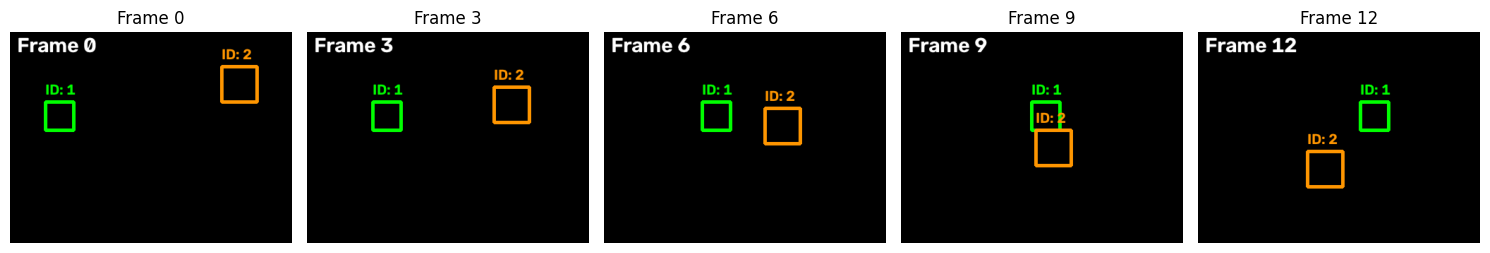

SUCCESS: Object IDs remain stable even after intersection!


In [5]:
class Track:
    def __init__(self, track_id, bbox):
        self.track_id = track_id
        self.age = 0
        self.hits = 1
        self.time_since_update = 0
        
        # Initialize Kalman
        self.kf = KalmanFilter(dim_x=7, dim_z=4)
        self.kf.F = np.eye(7)
        for i in range(3): self.kf.F[i, i+4] = 1 # State: [x,y,s,r, dx,dy,ds]
        self.kf.H = np.zeros((4, 7))
        for i in range(4): self.kf.H[i, i] = 1
        
        # Format: Center X, Center Y, Scale (Area), Ratio
        w, h = bbox[2]-bbox[0], bbox[3]-bbox[1]
        self.kf.x[:4] = np.array([[bbox[0]+w/2], [bbox[1]+h/2], [w*h], [w/h]])

    def predict(self):
        self.kf.predict()
        self.age += 1
        self.time_since_update += 1
        return self.get_state()

    def update(self, bbox):
        self.time_since_update = 0
        self.hits += 1
        w, h = bbox[2]-bbox[0], bbox[3]-bbox[1]
        self.kf.update(np.array([[bbox[0]+w/2], [bbox[1]+h/2], [w*h], [w/h]]))

    def get_state(self):
        x, y, s, r = self.kf.x[:4].flatten()
        w = np.sqrt(s * r)
        h = s / w
        return [x-w/2, y-h/2, x+w/2, y+h/2]

class SimpleSORT:
    def __init__(self, max_age=5, iou_thresh=0.3):
        self.tracks = []
        self.next_id = 1
        self.max_age = max_age
        self.iou_thresh = iou_thresh

    def update(self, detections):
        # 1. Predict all tracks
        predicted_boxes = [trk.predict() for trk in self.tracks]
        
        # 2. Hungarian Matching
        matched, unmatched_dets, unmatched_trks = [], list(range(len(detections))), list(range(len(self.tracks)))
        if len(self.tracks) > 0 and len(detections) > 0:
            iou_mat = np.zeros((len(self.tracks), len(detections)))
            for t, trk_box in enumerate(predicted_boxes):
                for d, det_box in enumerate(detections):
                    iou_mat[t, d] = calculate_iou(trk_box, det_box)
            
            row_ind, col_ind = linear_sum_assignment(-iou_mat) # Maximize IoU -> Minimize -IoU
            
            unmatched_dets, unmatched_trks = [], []
            for t, d in zip(row_ind, col_ind):
                if iou_mat[t, d] >= self.iou_thresh:
                    matched.append((t, d))
                else:
                    unmatched_trks.append(t)
                    unmatched_dets.append(d)
            # Add leftover tracks/dets
            unmatched_trks += list(set(range(len(self.tracks))) - set(row_ind))
            unmatched_dets += list(set(range(len(detections))) - set(col_ind))

        # 3. Update Matched Tracks
        for t, d in matched:
            self.tracks[t].update(detections[d])

        # 4. Create New Tracks
        for d in unmatched_dets:
            self.tracks.append(Track(self.next_id, detections[d]))
            self.next_id += 1

        # 5. Delete Dead Tracks
        self.tracks = [t for t in self.tracks if t.time_since_update <= self.max_age]
        
        return [(t.get_state(), t.track_id) for t in self.tracks if t.time_since_update == 0]

# --- SYNTHETIC VIDEO & PIPELINE TEST ---
tracker = SimpleSORT()
vis_frames = []

for frame_idx in range(15):
    # Create black background
    frame = np.zeros((300, 400, 3), dtype=np.uint8)
    detections = []
    
    # Object 1 (Moves Right)
    x1, y1 = 50 + frame_idx * 15, 100
    detections.append([x1, y1, x1+40, y1+40])
    
    # Object 2 (Moves Down-Left, Crossing Object 1 at frame 7!)
    x2, y2 = 300 - frame_idx * 12, 50 + frame_idx * 10
    detections.append([x2, y2, x2+50, y2+50])
    
    # Update Tracker
    active_tracks = tracker.update(detections)
    
    # Visualization
    for bbox, t_id in active_tracks:
        x, y, xmax, ymax = map(int, bbox)
        color = (0, 255, 0) if t_id == 1 else (0, 150, 255)
        cv2.rectangle(frame, (x, y), (xmax, ymax), color, 3)
        cv2.putText(frame, f"ID: {t_id}", (x, y-10), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)
        
    cv2.putText(frame, f"Frame {frame_idx}", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 1, (255,255,255), 2)
    if frame_idx % 3 == 0: vis_frames.append(frame)

show_frames(vis_frames, [f"Frame {i*3}" for i in range(len(vis_frames))], cols=5)
print("SUCCESS: Object IDs remain stable even after intersection!")

## Day 22 & 23 — Tracking Evaluation & ByteTrack
**Topics:** MOTChallenge, Multi-Object Tracking Evaluation, ByteTrack Analysis

### 1. Tracking Failure Analysis
When your tracker fails, you must identify which layer of the pipeline broke:
1. **Detection Failure:** YOLO entirely misses a person in shadow. (Fix: Better training data or lower conf threshold).
2. **Association Failure (ID Switch):** Two people cross, and the Hungarian matrix matches them to the wrong tracks because they look physically identical and occupy the same space. (Fix: DeepSORT - Add ReID / Cosine Similarity embedding).
3. **Prediction Failure:** A car turns a sharp 90-degree corner rapidly. The Linear Kalman Filter predicts it went straight, moving the predicted box away from the YOLO box, causing a missed match. (Fix: Extended Kalman Filter).
4. **Lifecycle Failure (Fragmentation):** A person goes behind a wall for 60 frames. The tracker `max_age` is 30. The track dies. When the person emerges, they get a *new* ID.

### 2. ByteTrack Revolution (The Two-Pass Match)
Standard SORT deletes YOLO detections if their confidence is below 0.5. 
* **The Problem:** If an object is partially occluded, YOLO's confidence drops to 0.3. SORT deletes it, and the track is starved of updates.
* **ByteTrack's Solution:** It keeps *all* detections. 
  * **Pass 1:** Match High-Confidence detections (>0.5) to existing tracks using IoU.
  * **Pass 2:** Take the *remaining unmatched tracks* (which are probably occluded) and try to match them with the Low-Confidence detections (0.1 to 0.5). 
  * This simple logic revolutionized tracking, allowing recovery of heavily occluded objects without heavy neural networks!

In [6]:
video_path = "data/videos/people-detection.mp4"

print("--- STARTING REAL VIDEO TRACKING (CUSTOM SORT) ---")
cap = cv2.VideoCapture(video_path)
w, h, fps = (int(cap.get(x)) for x in (cv2.CAP_PROP_FRAME_WIDTH, cv2.CAP_PROP_FRAME_HEIGHT, cv2.CAP_PROP_FPS))
out_path = 'data/videos/sort_output.mp4'
out = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))

yolo_model = YOLO('yolov8n.pt')
tracker_real = SimpleSORT(max_age=15, iou_thresh=0.3)

frame_count = 0
while cap.isOpened() and frame_count < 90: # Process only the first 3 seconds to save time
    ret, frame = cap.read()
    if not ret: break
    
    # 1. YOLO Detection (Filter only class 0: person)
    results = yolo_model(frame, classes=[0], verbose=False)[0]
    
    # Extract bounding boxes for high-confidence detections
    detections = [box.xyxy[0].cpu().numpy() for box in results.boxes if box.conf[0] > 0.4]
    
    # 2. Tracking Update
    active_tracks = tracker_real.update(detections)
    
    # 3. Visualization
    for bbox, t_id in active_tracks:
        x1, y1, x2, y2 = map(int, bbox)
        cv2.rectangle(frame, (x1, y1), (x2, y2), (255, 0, 150), 2)
        cv2.putText(frame, f"ID: {t_id}", (x1, max(20, y1-10)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
        
    out.write(frame)
    frame_count += 1

cap.release()
out.release()
print(f"SUCCESS: Custom SORT tracking video saved to '{out_path}'")

--- STARTING REAL VIDEO TRACKING (CUSTOM SORT) ---
SUCCESS: Custom SORT tracking video saved to 'data/videos/sort_output.mp4'


In [7]:
print("--- STARTING BYTETRACK PIPELINE ---")
# Run Ultralytics Native ByteTrack on the same video
track_results = yolo_model.track(
    source=video_path,
    classes=[0],               # Track people only
    tracker="bytetrack.yaml",  # The magic parameter!
    conf=0.25,                 # Lower confidence allowed because ByteTrack handles low-conf boxes in pass 2
    save=True,                 # Automatically save the output video
    project="data/videos",
    name="bytetrack_output",
    exist_ok=True,
    verbose=False
)

print("SUCCESS: ByteTrack processing complete! Check the 'data/videos/bytetrack_output' folder.")

# --- FAILURE ANALYSIS WORKSHOP ---
print("\n--- TRACKING FAILURE ANALYSIS CHECKLIST ---")
print("When evaluating on MOTChallenge, if your tracker fails, ask these 4 questions:")
print("1. Did ID 5 change to ID 8 after crossing behind a sign? -> ASSOCIATION FAILURE (Fix: Add DeepSORT ReID/Cosine Similarity).")
print("2. Did the bounding box jump off the person during a fast sprint? -> PREDICTION FAILURE (Fix: Tune Kalman Filter Q matrix).")
print("3. Did the box completely disappear in the shadow? -> DETECTION FAILURE (Fix: Lower YOLO conf threshold or retrain model).")
print("4. Did a person get a new ID after standing still behind a truck for 3 minutes? -> LIFECYCLE FAILURE (Fix: Increase tracker max_age).")

--- STARTING BYTETRACK PIPELINE ---
WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /home/norbert/Projects/computer_vision_oly/object_tracking/runs/detect/data/videos/bytetrack_output
SUCCESS: ByteTrack processing complete! Check the 'data/videos/bytetrack_output' folder.

--- TRACKING FAILURE ANALYSIS CHECKLIST ---
When evaluating on MOTChallenge, if your tracker fails, ask these 4 questions:
1. Did ID 5 change to ID 8 after crossing behind a sign? -> ASSOCIATION FAILURE (Fix: Add Dee

---
# PART II — The Ultralytics Tracking Toolbox & Modern Trackers
Everything up to this point was **built from scratch**: centroid matching → IoU matrices → Hungarian assignment → Kalman filters → a hand-written SORT → a ByteTrack-style second pass. That was deliberate. A tracker is no longer a black box once you have written one.

In Part II we move to the **production tooling**. Ultralytics YOLO ships **six built-in trackers** behind a single argument (`tracker="....yaml"`). Each one is a different answer to the same question: *"Given the boxes from the detector in this frame, which existing identity does each box belong to?"* — and each answer trades off **speed**, **robustness to camera motion**, **robustness to occlusion**, and **robustness to look-alike objects**.

**What you will learn in Part II**

| Day | Topic |
|---|---|
| 24 | The `model.track()` API, the `Results` object, and the `persist` / `stream` arguments |
| 25 | The six supported trackers side-by-side + a decision flow for choosing one |
| 26 | **BoT-SORT** — camera-motion compensation and optional ReID |
| 27 | **ByteTrack** — the two-stage "rescue low-confidence boxes" idea |
| 28 | **OC-SORT** — observation-centric corrections (ORU, OCM, OCR) |
| 29 | **Deep OC-SORT** — OC-SORT + appearance + camera motion |
| 30 | **FastTracker** — occlusion-aware ByteTrack with Kalman rollback |
| 31 | **TrackTrack** — track-perspective multi-cue association (the default tracker) |
| 32 | Customising tracker YAML files and benchmarking all six on your own video |
| 33 | Drawing trajectories (track trails) |
| 34 | Running trackers in multiple threads |
| 35 | Classic **OpenCV** single-object trackers (BOOSTING … MOSSE) |
| 36 | Evaluation metrics (MOTA, IDF1, HOTA, ID switches) with a mini evaluator |
| 37 | Cheat-sheet, troubleshooting guide, and exercises |

> **How to read the demos.** For each tracker there are two kinds of code cells:
> 1. **Concept demos** — small, self-contained NumPy/OpenCV experiments that reproduce the *idea* of the tracker (e.g. camera-motion compensation, observation-centric re-update). They run instantly, need no video and no GPU, and let you *see* why the trick works. They are **simplified teaching versions**, not copies of the Ultralytics source.
> 2. **Ultralytics cells** — the real thing, using `model.track(...)`. These need the weights and a video at `VIDEO_PATH`.

In [8]:
# ── Part II setup ──────────────────────────────────────────────────────────────
import time
import threading
from pathlib import Path
from collections import defaultdict

import yaml
import pandas as pd

# YOLO26 is used in the Ultralytics docs. If your installed `ultralytics` is older and
# cannot find the weights, switch to "yolov8n.pt" — every tracker below works with either.
MODEL_WEIGHTS = "yolo26n.pt"
VIDEO_PATH    = "data/videos/people-detection.mp4"   # same video used in Day 21-23
OUT_DIR       = Path("data/videos")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Setup complete. Model:", MODEL_WEIGHTS, "| Video:", VIDEO_PATH)

Setup complete. Model: yolo26n.pt | Video: data/videos/people-detection.mp4


## Day 24 — The Ultralytics Tracking API

**Topics:** `model.track()`, `Results.boxes.id`, `persist`, `stream`, tracking-by-detection in one call

### 1. Tracking-by-detection: what `model.track()` really does
Every tracker in this notebook (including the ones you wrote yourself) follows the same **tracking-by-detection** loop:

```
frame ─► detector (YOLO) ─► boxes + scores + classes
                               │
                               ▼
                    tracker.update(boxes, scores, [features])
                               │
                               ▼
          boxes + scores + classes + TRACK ID  (what you get back)
```

`model.predict(...)` stops after the detector. `model.track(...)` is *the same call plus a tracker object* that is created once, kept alive between frames, and fed the detections of every frame. The only thing that changes in the output is that each box gains an **`id`**.

### 2. The most important arguments
| Argument | Meaning | Typical use |
|---|---|---|
| `source` | Video path, webcam index (`0`), RTSP/HTTP URL, folder of images, or a single frame (NumPy array) | `source="video.mp4"` |
| `tracker` | Name or path of a tracker YAML. Choose the algorithm and its hyper-parameters | `"bytetrack.yaml"`, `"my_botsort.yaml"` |
| `persist` | **Keep the tracker's memory between calls.** Required when *you* feed frames one at a time | `persist=True` inside a `while cap.read()` loop |
| `stream` | Return a *generator* of `Results` instead of a list. Essential for long videos / live feeds (otherwise every frame's result is kept in RAM) | `stream=True` |
| `conf` | Minimum detector confidence. **Lower it for ByteTrack-style trackers** — they can use low-score boxes | `conf=0.25` (or lower) |
| `iou` | NMS IoU threshold *inside the detector* (not the tracker's matching threshold!) | `iou=0.7` |
| `classes` | Keep only these class IDs (e.g. `[0]` = person in COCO) | `classes=[0]` |
| `save` / `show` | Write the annotated video / pop up a window | `save=True` |
| `imgsz`, `device`, `half` | Speed / accuracy knobs inherited from the detector | `imgsz=640` |

### 3. `persist=True` — the single most common beginner bug
* If you pass a **whole video** (`source="video.mp4"`), Ultralytics iterates over the frames itself and the tracker lives for the entire call. You do **not** need `persist`.
* If **you** loop over frames and call `model.track(frame)` once per frame, then **without `persist=True` the tracker is re-created on every call**, so every frame starts from scratch and you get IDs `1, 2, 3, …` over and over again with no continuity.
* Conversely, when you move to a **new video** with `persist=True` you should create a fresh `YOLO(...)` object (or reset the tracker) — otherwise old tracks leak into the new clip.

### 4. Reading the result
For each frame you get a `Results` object. The relevant fields:
* `r.boxes.xyxy`, `r.boxes.xywh`, `r.boxes.conf`, `r.boxes.cls` — as with plain detection.
* `r.boxes.id` — tensor of track IDs, or **`None`** when there are no confirmed tracks in that frame.
* `r.boxes.is_track` — a convenient boolean: `True` only if IDs are present. **Always test this before touching `.id`**, otherwise `None.int()` will crash on frames with no detections.
* `r.plot()` — returns the frame (BGR `ndarray`) with boxes and `id:` labels already drawn.

In [9]:
# 1) Inspect what a tracked Results object contains (streaming = low memory)
model = YOLO(MODEL_WEIGHTS)

stream = model.track(
    source=VIDEO_PATH,
    tracker="bytetrack.yaml",
    classes=[0],          # people only
    conf=0.25,
    stream=True,          # generator -> frames are processed lazily
    verbose=False,
)

for frame_idx, r in enumerate(stream):
    b = r.boxes
    print(f"frame {frame_idx:02d} | boxes: {len(b):2d} | has track IDs: {b.is_track}")
    if b.is_track:                                   # <- ALWAYS guard before using b.id
        for tid, cls, conf, xyxy in zip(b.id.int().tolist(), b.cls.int().tolist(),
                                        b.conf.tolist(), b.xyxy.tolist()):
            print(f"      ID {tid:>3} | class {cls} | conf {conf:.2f} | box {[round(v) for v in xyxy]}")
    if frame_idx >= 4:
        break

frame 00 | boxes:  0 | has track IDs: False
frame 01 | boxes:  0 | has track IDs: False
frame 02 | boxes:  0 | has track IDs: False
frame 03 | boxes:  0 | has track IDs: False
frame 04 | boxes:  0 | has track IDs: False


In [10]:
# 2) Frame-by-frame control with persist=True (needed when YOU own the loop,
#    e.g. to draw custom overlays, count line crossings, or read a camera yourself)
cap   = cv2.VideoCapture(VIDEO_PATH)
model = YOLO(MODEL_WEIGHTS)                       # fresh model => fresh tracker state

ids_per_frame = []
while cap.isOpened() and len(ids_per_frame) < 60:
    ok, frame = cap.read()
    if not ok:
        break
    r = model.track(frame, persist=True, tracker="bytetrack.yaml", classes=[0], verbose=False)[0]
    ids_per_frame.append(r.boxes.id.int().tolist() if r.boxes.is_track else [])
cap.release()

all_ids = sorted({i for ids in ids_per_frame for i in ids})
print(f"Processed {len(ids_per_frame)} frames | distinct IDs seen: {len(all_ids)} -> {all_ids}")
print("IDs in the last frame:", ids_per_frame[-1])

# Try it yourself: remove `persist=True` above and re-run. The IDs will restart at 1 on every frame,
# because a brand-new tracker is created for each call.

Processed 60 frames | distinct IDs seen: 1 -> [2]
IDs in the last frame: [2]


## Day 25 — Supported Trackers & How to Choose One

**Topics:** Six built-in trackers, feature matrix, decision flow, switching trackers with one argument

Ultralytics YOLO ships with **six built-in trackers**. You enable one by passing its YAML config file to the `tracker` argument.

| Tracker | Config file | Motion model | Appearance / ReID | Camera-motion compensation | Occlusion handling |
|---|---|---|---|---|---|
| **BoT-SORT** | `botsort.yaml` | Linear Kalman | Optional (`with_reid`) | Configurable (`gmc_method`) | Track buffer + ReID rebinding |
| **ByteTrack** | `bytetrack.yaml` | Linear Kalman | None | No | Two-stage low-confidence rescue |
| **OC-SORT** | `ocsort.yaml` | Observation-centric Kalman | None | No | ORU, OCM, OCR re-update from last observation |
| **Deep OC-SORT** | `deepocsort.yaml` | Observation-centric Kalman | Optional (`with_reid`) | Configurable (`gmc_method`) | OC-SORT + optional adaptive appearance EMA |
| **FastTracker** | `fasttrack.yaml` | Linear Kalman + rollback | None | No | Kalman rollback + bbox enlargement on occlusion |
| **TrackTrack** | `tracktrack.yaml` | Linear Kalman (NSA) | Optional (`with_reid`) | Configurable (`gmc_method`) | Iterative multi-cue association + TAI |

> **Default:** `tracktrack.yaml` is used when you pass no `tracker` argument (in older Ultralytics releases the default was `botsort.yaml`, so check your version).

### Reading the table — what each column means
* **Motion model** — how the tracker *predicts* where a track will be in the next frame (Day 19). *Linear Kalman* assumes constant velocity. *Observation-centric* Kalman (OC-SORT) additionally corrects the filter using the last **real observation** rather than trusting its own drifting estimate. *NSA* ("noise scale adaptive", an idea popularised by StrongSORT) Kalman scales the measurement noise with the detector's confidence so uncertain boxes are trusted less.
* **Appearance / ReID** — whether the tracker can compare *what objects look like* (an embedding vector per box) in addition to *where they are*. This is what separates two people wearing the same colours who cross paths. It costs extra compute, so it is **optional/off by default** wherever it exists.
* **Camera-motion compensation (CMC / GMC)** — if the camera itself moves (handheld, drone, pan-tilt), *every* box shifts even if the objects are standing still. CMC estimates that global shift and removes it from the Kalman predictions before matching.
* **Occlusion handling** — what happens when objects overlap or the detector misses them: rescuing low-score boxes (ByteTrack), re-updating from the last real observation (OC-SORT), rolling the filter back (FastTracker), matching with several cues iteratively (TrackTrack), or re-identifying by appearance (BoT-SORT/Deep OC-SORT).

### Which tracker should I use?
Use this flow to pick a **starting point** (then measure — Day 32 and Day 36 show how):

1. **Need the fastest, simplest baseline?** → **ByteTrack** (no ReID, no camera-motion compensation, minimum overhead).
2. **Handheld, drone, or moving-camera footage?** → **BoT-SORT** (adds camera-motion compensation and optional ReID).
3. **Non-linear motion** (sports, dancing, abrupt turns) **and no ReID budget?** → **OC-SORT** (observation-centric corrections without appearance cost).
4. **Crowded moving-camera scenes where ID swaps are the main problem?** → **Deep OC-SORT** or **TrackTrack** (both support optional appearance matching; TrackTrack also adds multi-cue association and duplicate-ID suppression).
5. **Frequent partial overlap in real time, no ReID budget?** → **FastTracker** (occlusion-aware ByteTrack variant with Kalman rollback).

No flow chart survives contact with real data — treat it as a **prior**, not a verdict.

In [11]:
TRACKER_CONFIGS = {
    "BoT-SORT":     "botsort.yaml",
    "ByteTrack":    "bytetrack.yaml",
    "OC-SORT":      "ocsort.yaml",
    "Deep OC-SORT": "deepocsort.yaml",
    "FastTracker":  "fasttrack.yaml",
    "TrackTrack":   "tracktrack.yaml",
}

def recommend_tracker(moving_camera=False, nonlinear_motion=False, crowded=False,
                      frequent_overlap=False, reid_budget=False, need_fastest=False):
    """Encode the decision flow above as code. Returns (yaml_file, reason)."""
    if need_fastest:
        return "bytetrack.yaml", "Lowest overhead: no ReID, no camera-motion compensation."
    if moving_camera and crowded:
        return "tracktrack.yaml", ("Crowded + moving camera: multi-cue association, duplicate-ID suppression "
                                   "(Deep OC-SORT is the alternative if you prefer OC-SORT-style motion).")
    if moving_camera:
        return "botsort.yaml", "Moving camera: camera-motion compensation (+ optional ReID)."
    if nonlinear_motion and not reid_budget:
        return "ocsort.yaml", "Non-linear motion without appearance cost: observation-centric corrections."
    if frequent_overlap and not reid_budget:
        return "fasttrack.yaml", "Frequent partial overlap, real time, no ReID: Kalman rollback on occlusion."
    if crowded:
        return "tracktrack.yaml", "Crowded scene with duplicate-ID risk: track-aware initialisation."
    return "bytetrack.yaml", "No special condition: start with the simple baseline."

scenarios = {
    "CCTV, static camera, need max FPS":         dict(need_fastest=True),
    "Drone footage of a parking lot":            dict(moving_camera=True),
    "Basketball game (abrupt direction changes)": dict(nonlinear_motion=True),
    "Supermarket queue, people overlap often":    dict(frequent_overlap=True),
    "Handheld camera in a crowded festival":      dict(moving_camera=True, crowded=True),
}
for name, flags in scenarios.items():
    cfg, why = recommend_tracker(**flags)
    print(f"{name:<45} -> {cfg:<16} | {why}")

CCTV, static camera, need max FPS             -> bytetrack.yaml   | Lowest overhead: no ReID, no camera-motion compensation.
Drone footage of a parking lot                -> botsort.yaml     | Moving camera: camera-motion compensation (+ optional ReID).
Basketball game (abrupt direction changes)    -> ocsort.yaml      | Non-linear motion without appearance cost: observation-centric corrections.
Supermarket queue, people overlap often       -> fasttrack.yaml   | Frequent partial overlap, real time, no ReID: Kalman rollback on occlusion.
Handheld camera in a crowded festival         -> tracktrack.yaml  | Crowded + moving camera: multi-cue association, duplicate-ID suppression (Deep OC-SORT is the alternative if you prefer OC-SORT-style motion).


### Swapping trackers is a one-argument change
Because every tracker sits behind the same interface, comparing them costs one line each. **Important:** create a **fresh `YOLO` object per run** (or at least do not reuse `persist=True` state) so one tracker's memory never leaks into the next experiment.

In [12]:
# The minimal "try them all" pattern from the docs
model = YOLO(MODEL_WEIGHTS)
results = model.track(source=VIDEO_PATH, tracker="bytetrack.yaml")
results = model.track(source=VIDEO_PATH, tracker="ocsort.yaml")
results = model.track(source=VIDEO_PATH, tracker="tracktrack.yaml")
# NOTE: each call without persist=True builds a new tracker, so the three runs are independent.


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/596) /home/norbert/Projects/computer_vision_oly/object_tracking/data/videos/people-detection.mp4: 384x640 (no detections), 4.6ms
video 1/1 (frame 2/596) /home/norbert/Projects/computer_vision_oly/object_tracking/data/videos/people-detection.mp4: 384x640 (no detections), 5.2ms
video 1/1 (frame 3/596) /home/norbert/Projects/computer_vision_oly/object_tracking/data/videos/people-detection.mp4: 384x640 (no detections), 5.8ms
video 1/1 (fra

RuntimeError: 
  #ifdef __HIPCC__
  #define ERROR_UNSUPPORTED_CAST ;
  // corresponds to aten/src/ATen/native/cuda/thread_constants.h
  #define CUDA_OR_ROCM_NUM_THREADS 256
  // corresponds to aten/src/ATen/cuda/detail/OffsetCalculator.cuh
  #define MAX_DIMS 16
  #ifndef __forceinline__
  #define __forceinline__ inline __attribute__((always_inline))
  #endif
  #else
  #define ERROR_UNSUPPORTED_CAST __trap();
  #define CUDA_OR_ROCM_NUM_THREADS 128
  #define MAX_DIMS 25
  #endif
  #define POS_INFINITY __int_as_float(0x7f800000)
  #define INFINITY POS_INFINITY
  #define NEG_INFINITY __int_as_float(0xff800000)
  #define NAN __int_as_float(0x7fffffff)

  typedef long long int int64_t;
  typedef unsigned int uint32_t;
  typedef signed char int8_t;
  typedef unsigned char uint8_t;  // NOTE: this MUST be "unsigned char"! "char" is equivalent to "signed char"
  typedef short int16_t;
  typedef unsigned short uint16_t;
  typedef unsigned long long uint64_t;
  static_assert(sizeof(int64_t) == 8, 

### Measuring a tracker without ground truth
You rarely have ground-truth annotations on your own video. You can still compute **proxy statistics** that correlate with tracking quality:

| Proxy metric | How to read it |
|---|---|
| **Unique IDs** | For a scene with ~N people it should be *close to N plus the number of people who entered/left*. Far more means **fragmentation** (identity re-created after being lost) or **duplicate IDs**. |
| **Mean / median track length** | Longer is usually better. A very low median means many short-lived "ghost" tracks. |
| **Short tracks (< 10 frames)** | Typically false positives or flicker. |
| **Tracks with gaps** | An ID that disappears and re-appears was *re-associated* — good (it survived an occlusion), but a high count may also signal an unstable detector. |
| **FPS** | End-to-end speed including the detector. To isolate tracker overhead, compare against `model.predict` on the same clip. |

These do **not** replace MOTA / IDF1 / HOTA (Day 36) — they only tell you *which tracker deserves a closer look*.

In [ ]:
def run_tracker(tracker_cfg, video=VIDEO_PATH, max_frames=150, weights=MODEL_WEIGHTS, **track_kwargs):
    """Run one tracker on the first `max_frames` frames; return (ids_per_frame, seconds)."""
    model = YOLO(weights)                          # fresh model => fresh tracker state
    ids_per_frame, t0 = [], time.perf_counter()
    for r in model.track(source=video, tracker=tracker_cfg, stream=True, verbose=False,
                         classes=[0], conf=0.25, **track_kwargs):
        ids_per_frame.append(r.boxes.id.int().tolist() if r.boxes.is_track else [])
        if len(ids_per_frame) >= max_frames:
            break
    return ids_per_frame, time.perf_counter() - t0


def summarize_ids(ids_per_frame):
    """Proxy statistics computed purely from the per-frame list of track IDs."""
    lifetime, first, last = defaultdict(int), {}, {}
    for f, ids in enumerate(ids_per_frame):
        for i in ids:
            lifetime[i] += 1
            first.setdefault(i, f)
            last[i] = f
    lengths = np.array(list(lifetime.values())) if lifetime else np.array([0])
    with_gaps = sum(1 for i in lifetime if (last[i] - first[i] + 1) != lifetime[i])
    return dict(unique_ids=len(lifetime),
                mean_track_len=round(float(lengths.mean()), 1),
                median_track_len=float(np.median(lengths)),
                short_tracks_lt10=int((lengths < 10).sum()),
                tracks_with_gaps=with_gaps,
                avg_people_per_frame=round(float(np.mean([len(x) for x in ids_per_frame])), 2) if ids_per_frame else 0)

# --- sanity check of the helper on fake data (runs without YOLO) -----------------------------
fake = [[1, 2], [1, 2], [1], [1, 3], [1, 3], [1, 3]]        # ID 2 vanishes; ID 3 appears
print(summarize_ids(fake))

{'unique_ids': 3, 'mean_track_len': 3.7, 'median_track_len': 3.0, 'short_tracks_lt10': 3, 'tracks_with_gaps': 0, 'avg_people_per_frame': 1.83}


In [ ]:
# Run all six trackers on the same clip and compare proxy statistics + speed
rows = []
for name, cfg in TRACKER_CONFIGS.items():
    ids, secs = run_tracker(cfg, max_frames=150)
    stats = summarize_ids(ids)
    stats.update(tracker=name, fps=round(len(ids) / secs, 1))
    rows.append(stats)
    print(f"{name:<13} done: {len(ids)} frames in {secs:.1f}s")

df_compare = pd.DataFrame(rows).set_index("tracker")
display(df_compare)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df_compare["unique_ids"].plot.bar(ax=axes[0], title="Unique IDs (lower ≈ less fragmentation)", color="tab:orange")
df_compare["median_track_len"].plot.bar(ax=axes[1], title="Median track length (higher is better)", color="tab:green")
df_compare["fps"].plot.bar(ax=axes[2], title="End-to-end FPS (detector + tracker)", color="tab:blue")
for ax in axes: ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

BoT-SORT      done: 150 frames in 1.9s
ByteTrack     done: 150 frames in 1.2s
OC-SORT       done: 150 frames in 1.3s
Deep OC-SORT  done: 150 frames in 1.2s
FastTracker   done: 150 frames in 1.2s


RuntimeError: 
  #ifdef __HIPCC__
  #define ERROR_UNSUPPORTED_CAST ;
  // corresponds to aten/src/ATen/native/cuda/thread_constants.h
  #define CUDA_OR_ROCM_NUM_THREADS 256
  // corresponds to aten/src/ATen/cuda/detail/OffsetCalculator.cuh
  #define MAX_DIMS 16
  #ifndef __forceinline__
  #define __forceinline__ inline __attribute__((always_inline))
  #endif
  #else
  #define ERROR_UNSUPPORTED_CAST __trap();
  #define CUDA_OR_ROCM_NUM_THREADS 128
  #define MAX_DIMS 25
  #endif
  #define POS_INFINITY __int_as_float(0x7f800000)
  #define INFINITY POS_INFINITY
  #define NEG_INFINITY __int_as_float(0xff800000)
  #define NAN __int_as_float(0x7fffffff)

  typedef long long int int64_t;
  typedef unsigned int uint32_t;
  typedef signed char int8_t;
  typedef unsigned char uint8_t;  // NOTE: this MUST be "unsigned char"! "char" is equivalent to "signed char"
  typedef short int16_t;
  typedef unsigned short uint16_t;
  typedef unsigned long long uint64_t;
  static_assert(sizeof(int64_t) == 8, 

## Day 26 — BoT-SORT: Camera-Motion Compensation + Optional ReID

**Topics:** Global motion compensation (GMC/CMC), sparse optical flow, affine warp of Kalman states, appearance fusion, `with_reid`

BoT-SORT (*Aharon et al., 2022*) extends **ByteTrack** with two ideas aimed at real-world footage:

### 1. Camera Motion Compensation (CMC)
**The problem.** The Kalman filter predicts "this person will be 3 px to the right next frame". But if the camera pans right by 40 px, the person *actually* appears 37 px to the *left* in the image. Prediction and detection no longer overlap, IoU collapses to ~0, and the tracker believes every object vanished and a hundred new ones appeared.

**The fix.** Every frame, estimate the **global image motion** between frame *t−1* and frame *t* and apply that same transformation to every Kalman state *before* computing IoU.
1. Detect many corner-like feature points on the *previous* frame (e.g. Shi-Tomasi corners).
2. Track them into the *current* frame (**sparse optical flow**, Lucas-Kanade).
3. Fit a robust **affine** transform (translation + rotation + scale) to the point pairs with RANSAC so that independently moving objects (people!) are rejected as outliers and the background wins.
4. Warp the predicted boxes with that transform.

Available back-ends (`gmc_method`): `sparseOptFlow` (default — fast and good), `orb`, `sift` (feature matching), `ecc` (dense image alignment; more accurate on difficult motion but slower), and `none` (disable).

### 2. Optional appearance matching (ReID)
With `with_reid: True`, an **embedding** (a feature vector describing *how the object looks*) is computed for every detection. When two boxes overlap enough that IoU alone is ambiguous, the cosine similarity of embeddings breaks the tie. Two gates control this:
* `proximity_thresh` — appearance is only consulted when the IoU is at least this large (no point comparing looks of objects 500 px apart).
* `appearance_thresh` — the minimum *normalised appearance similarity* required to accept a ReID match. **Raise it to be stricter.**

`model: auto` reuses the detector's own features (no second network, little overhead); you may instead pass a path to a dedicated ReID model (`.pt` checkpoint or a compatible export).

**Best for:** general-purpose tracking, especially **moving cameras**. Add ReID **only** when look-alike crowds cause ID swaps.

### BoT-SORT-specific arguments
| Parameter | Valid values | Description |
|---|---|---|
| `gmc_method` | `sparseOptFlow`, `orb`, `sift`, `ecc`, `none` | Camera-motion-compensation back-end. `sparseOptFlow` is the default. `none` disables CMC. |
| `with_reid` | `True`, `False` | Enable appearance-based matching. Off by default. |
| `model` | `auto` or compatible ReID model path | `auto` uses native YOLO features when available; custom models can be `.pt` checkpoints or compatible exports. |
| `proximity_thresh` | 0.0 – 1.0 | Minimum IoU before appearance features are considered. |
| `appearance_thresh` | 0.0 – 1.0 | Minimum normalised appearance similarity required for a ReID match. Raise to make matching stricter. |

### Tuning tips
* **Static camera:** set `gmc_method: none` to save a few ms per frame — there is no global motion to compensate.
* **Heavy camera motion:** keep `sparseOptFlow`; `ecc` is more accurate but slower.
* **Look-alike crowds:** turn on `with_reid: True` and raise `appearance_thresh` (e.g. `0.85+`).

Below we reproduce the **CMC idea** from scratch on a synthetic scene so you can *measure* what it buys you.

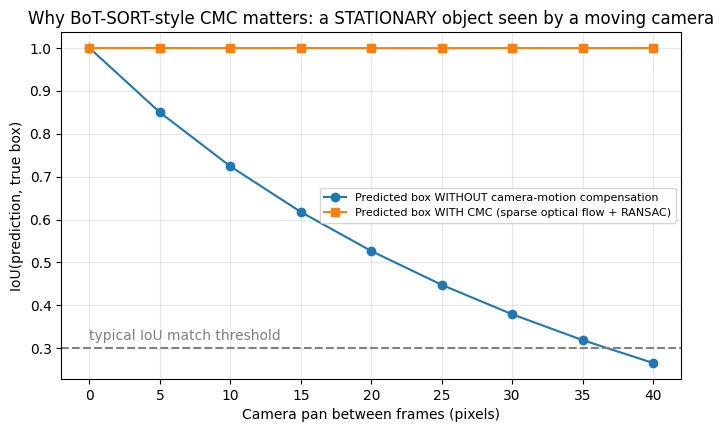

Last estimated transform (should be ≈ a pure translation of the pan):
 [[  1.   0. -40.]
 [ -0.   1. -16.]]


In [ ]:
# ── CONCEPT DEMO 1: Camera-Motion Compensation from scratch ─────────────────────────────────
def make_textured_world(h=480, w=640, seed=0):
    """A static 'world' full of blobs: gives optical flow something to lock onto."""
    rng = np.random.default_rng(seed)
    world = np.full((h, w), 30, np.uint8)
    for _ in range(350):
        cv2.circle(world, (int(rng.integers(0, w)), int(rng.integers(0, h))),
                   int(rng.integers(3, 10)), int(rng.integers(90, 255)), -1)
    return cv2.GaussianBlur(world, (3, 3), 0)

def camera_view(world, cam_x, cam_y):
    """What the camera sees when it is panned to (cam_x, cam_y): the world shifts the opposite way."""
    M = np.float32([[1, 0, -cam_x], [0, 1, -cam_y]])
    return cv2.warpAffine(world, M, (world.shape[1], world.shape[0]))

IDENTITY = np.array([[1, 0, 0], [0, 1, 0]], np.float32)

def estimate_cmc(prev_gray, curr_gray):
    """Sparse optical flow + RANSAC similarity transform (the `sparseOptFlow` recipe)."""
    pts0 = cv2.goodFeaturesToTrack(prev_gray, maxCorners=300, qualityLevel=0.01, minDistance=8)
    if pts0 is None:
        return IDENTITY
    pts1, status, _ = cv2.calcOpticalFlowPyrLK(prev_gray, curr_gray, pts0, None, winSize=(21, 21), maxLevel=3)
    good = status.ravel() == 1
    if good.sum() < 4:
        return IDENTITY
    A, _ = cv2.estimateAffinePartial2D(pts0[good], pts1[good], method=cv2.RANSAC, ransacReprojThreshold=3.0)
    return A if A is not None else IDENTITY

def warp_box(box, A):
    """Apply a 2x3 affine matrix to an xyxy box (via its four corners)."""
    x1, y1, x2, y2 = box
    corners = np.array([[x1, y1], [x2, y1], [x2, y2], [x1, y2]], np.float32)
    w = corners @ A[:, :2].T + A[:, 2]
    return [w[:, 0].min(), w[:, 1].min(), w[:, 0].max(), w[:, 1].max()]

world     = make_textured_world()
world_box = [250, 200, 330, 300]            # a parked car: STATIONARY in the world
speeds, iou_no_cmc, iou_cmc = list(range(0, 41, 5)), [], []

for s in speeds:
    cam_prev, cam_curr = (0, 0), (s, 0.4 * s)                          # camera pans between two frames
    prev_view, curr_view = camera_view(world, *cam_prev), camera_view(world, *cam_curr)
    prev_box = [world_box[0] - cam_prev[0], world_box[1] - cam_prev[1], world_box[2] - cam_prev[0], world_box[3] - cam_prev[1]]
    true_box = [world_box[0] - cam_curr[0], world_box[1] - cam_curr[1], world_box[2] - cam_curr[0], world_box[3] - cam_curr[1]]

    iou_no_cmc.append(calculate_iou(prev_box, true_box))               # tracker's prediction = "it hasn't moved"
    A = estimate_cmc(prev_view, curr_view)
    iou_cmc.append(calculate_iou(warp_box(prev_box, A), true_box))     # prediction after compensating the camera

plt.figure(figsize=(8, 4.5))
plt.plot(speeds, iou_no_cmc, "o-", label="Predicted box WITHOUT camera-motion compensation")
plt.plot(speeds, iou_cmc, "s-", label="Predicted box WITH CMC (sparse optical flow + RANSAC)")
plt.axhline(0.3, ls="--", c="gray"); plt.text(0, 0.32, "typical IoU match threshold", color="gray")
plt.xlabel("Camera pan between frames (pixels)"); plt.ylabel("IoU(prediction, true box)")
plt.title("Why BoT-SORT-style CMC matters: a STATIONARY object seen by a moving camera")
plt.legend(loc="center right", fontsize=8); plt.grid(alpha=.3); plt.show()
print("Last estimated transform (should be ≈ a pure translation of the pan):\n", np.round(A, 2))

**Reading the plot.** Without CMC the IoU between the (stale) prediction and the true box drops below 0.5 within ~20 px of pan and below a typical 0.3 matching gate by ~35–40 px (sooner for smaller objects, since the same shift is a bigger fraction of the box) — the tracker would drop the object and spawn a new ID. With CMC the prediction is warped by the estimated background motion and IoU stays near 1.0. That is *exactly* the work `gmc_method: sparseOptFlow` does for you each frame, and why a static CCTV camera can set `gmc_method: none` and save time.

**A limit worth knowing.** We only plotted pans up to 40 px *per frame*. In our test, pushing the range to 50 px and beyond made the Lucas-Kanade tracker lose the points (the estimated transform becomes garbage and CMC does *worse than nothing*). Sparse optical flow assumes small inter-frame motion; very fast pans, low frame rates, or frame skipping (`vid_stride`) call for feature matching (`orb` / `sift`) or dense alignment (`ecc`) — the other `gmc_method` options. Try extending `range(0, 41, 5)` to `range(0, 91, 10)` and watch it break.

### The appearance cue (ReID) — a minimal model
The cell below shows **why IoU alone is ambiguous** when two people cross and how an embedding resolves it. The fusion rule mirrors the BoT-SORT idea: appearance is consulted only inside the IoU gate (`proximity_thresh`), must exceed `appearance_thresh` to count, and the final cost takes the better (smaller) of the motion and appearance costs.

> This is a **teaching approximation** of the mechanism — thresholds, scaling and fusion details inside Ultralytics may differ.

In [ ]:
# ── CONCEPT DEMO 2: IoU alone vs IoU + appearance when two people cross ─────────────────────
rng = np.random.default_rng(3)
emb_A, emb_B = rng.normal(size=64), rng.normal(size=64)                 # two different-looking people

def l2norm(x): return x / np.linalg.norm(x, axis=-1, keepdims=True)

tracks_boxes = [[100, 100, 140, 180], [112, 100, 152, 180]]             # Track A (left), Track B (right)
tracks_embs  = l2norm(np.stack([emb_A, emb_B]))

# The two people have just crossed: detection 0 is *really* B but sits closer to A's old box.
dets_boxes = [[105, 100, 145, 180], [109, 100, 149, 180]]
dets_embs  = l2norm(np.stack([emb_B + 0.3 * rng.normal(size=64),        # really B
                              emb_A + 0.3 * rng.normal(size=64)]))      # really A

iou_mat  = np.array([[calculate_iou(t, d) for d in dets_boxes] for t in tracks_boxes])
iou_dist = 1.0 - iou_mat
similarity = 1.0 - (1.0 - tracks_embs @ dets_embs.T) / 2.0               # cosine sim mapped to [0, 1]

def fuse_iou_and_appearance(iou_dist, similarity, proximity_thresh=0.5, appearance_thresh=0.8):
    emb_cost = 1.0 - similarity
    emb_cost[similarity < appearance_thresh] = 1.0           # not similar enough -> no appearance evidence
    emb_cost[iou_dist > (1.0 - proximity_thresh)] = 1.0      # outside the IoU gate -> appearance not consulted
    return np.minimum(iou_dist, emb_cost)

names = ["A", "B"]
for label, cost in [("IoU only", iou_dist), ("IoU + appearance", fuse_iou_and_appearance(iou_dist, similarity))]:
    r_, c_ = linear_sum_assignment(cost)
    print(f"{label:<17}:", ", ".join(f"Track {names[t]} -> Det {d}" for t, d in zip(r_, c_)))

print("\nIoU matrix:\n", np.round(iou_mat, 2))
print("Appearance similarity:\n", np.round(similarity, 2))
print("\nGround truth: Track A -> Det 1, Track B -> Det 0 (they crossed). Only the appearance-aware cost gets it right.")

IoU only         : Track A -> Det 0, Track B -> Det 1
IoU + appearance : Track A -> Det 1, Track B -> Det 0

IoU matrix:
 [[0.78 0.63]
 [0.7  0.86]]
Appearance similarity:
 [[0.46 0.98]
 [0.98 0.46]]

Ground truth: Track A -> Det 1, Track B -> Det 0 (they crossed). Only the appearance-aware cost gets it right.


In [ ]:
# ── REAL BoT-SORT with Ultralytics ──────────────────────────────────────────────────────────
model = YOLO(MODEL_WEIGHTS)
results = model.track(
    source=VIDEO_PATH,
    tracker="botsort.yaml",      # default: sparseOptFlow camera-motion compensation, ReID OFF
    classes=[0], conf=0.25,
    save=True, project=str(OUT_DIR), name="botsort_default", exist_ok=True, verbose=False,
)
print("Saved to:", OUT_DIR / "botsort_default")
# Customised variants (static camera / ReID) are created from YAML in Day 32.

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /home/norbert/Projects/computer_vision_oly/object_tracking/runs/detect/data/videos/botsort_default
Saved to: data/videos/botsort_default


## Day 27 — ByteTrack: Rescuing Low-Confidence Detections

**Topics:** Two-stage association, high/low score split, why detectors "flicker", ByteTrack-style tracker from scratch

ByteTrack (*Zhang et al., ECCV 2022*) is the **lightweight baseline** of modern tracking. It uses a **linear Kalman filter + IoU** and **no appearance model and no camera-motion compensation**. Its single big idea is the two-stage association:

* **Stage 1** — match **high-score** detections against the active tracks.
* **Stage 2** — retry the **still-unmatched tracks** against the **low-score** detections. A person who is half-hidden behind a pillar still produces a box, just with a low score (0.2–0.5). Older trackers throw it away; ByteTrack uses it to *keep the identity alive*.

Equally important: **low-score boxes are never allowed to start new tracks** — a low score on an unmatched box is more likely a false positive (a shadow, a poster) than a new person.

(You met this idea in the markdown of Day 22 & 23. Here we build it and measure it.)

**Best for:** static or near-static cameras where **detector cost dominates** and you want minimum tracker overhead.

**ByteTrack-specific arguments:** none beyond the shared tracker arguments below.

### Shared tracker arguments (present in most tracker YAML files)
| Parameter | Meaning |
|---|---|
| `tracker_type` | Which algorithm the YAML selects (`bytetrack`, `botsort`, `ocsort`, …). |
| `track_high_thresh` | Score above which a detection is "high confidence" (stage 1; may start a track). |
| `track_low_thresh` | Lowest score still considered at all (stage 2 candidates). Below this the box is ignored. |
| `new_track_thresh` | Minimum score for an **unmatched** detection to become a new track. |
| `track_buffer` | How many frames a *lost* track is kept before deletion (the "memory"). Scales with FPS! |
| `match_thresh` | Matching-cost threshold for the assignment step (looser ↔ stricter). |
| `fuse_score` | Blend detection score into the IoU cost so confident boxes win ties. |

> Exact names/values can differ slightly between Ultralytics versions — Day 32 prints the YAML shipped with *your* install.

### Tuning tips
* **Noisy detector** → lower `track_low_thresh` so stage 2 has more candidates.
* **High-recall detector** → raise `track_high_thresh` to reduce fragmented IDs.
* **Frequent ID flicker** → raise `track_buffer` so briefly-missed tracks survive.

### Build it: `SimpleByteTrack` on top of your `SimpleSORT`
We subclass the tracker from Day 20-21. It receives `(boxes, scores)` instead of only boxes. We then replay a scenario in which a person's detection score **drops to 0.3** for 7 frames (partial occlusion) and compare:
* SORT-style: drop everything below 0.5, short memory (`max_age=3`);
* ByteTrack-style: same memory, but low-score rescue.

In [ ]:
class SimpleByteTrack(SimpleSORT):
    """Teaching version of ByteTrack's two-stage association (reuses Track + Kalman from Day 20-21)."""
    def __init__(self, max_age=5, iou_thresh=0.3, second_iou_thresh=0.3,
                 high_thresh=0.5, low_thresh=0.1):
        super().__init__(max_age=max_age, iou_thresh=iou_thresh)
        self.second_iou_thresh = second_iou_thresh
        self.high_thresh, self.low_thresh = high_thresh, low_thresh

    @staticmethod
    def _associate(trk_ids, pred_boxes, det_boxes, thresh):
        """Hungarian on (1 - IoU). Returns matches [(track_idx, det_idx)], unmatched tracks, unmatched dets."""
        if len(trk_ids) == 0 or len(det_boxes) == 0:
            return [], list(trk_ids), list(range(len(det_boxes)))
        iou = np.array([[calculate_iou(pred_boxes[t], d) for d in det_boxes] for t in trk_ids])
        rows, cols = linear_sum_assignment(-iou)
        matches, um_t, um_d = [], set(range(len(trk_ids))), set(range(len(det_boxes)))
        for i, j in zip(rows, cols):
            if iou[i, j] >= thresh:
                matches.append((trk_ids[i], j)); um_t.discard(i); um_d.discard(j)
        return matches, [trk_ids[i] for i in sorted(um_t)], sorted(um_d)

    def update(self, detections, scores):
        dets   = np.asarray(detections, dtype=float).reshape(-1, 4)
        scores = np.asarray(scores, dtype=float).reshape(-1)
        high_mask = scores >= self.high_thresh
        low_mask  = (scores >= self.low_thresh) & ~high_mask
        high_boxes, low_boxes = dets[high_mask], dets[low_mask]

        predicted = [trk.predict() for trk in self.tracks]          # 1. Kalman predict
        all_trks  = list(range(len(self.tracks)))

        # Stage 1: high-score detections <-> all tracks
        m1, unmatched_trks, unmatched_high = self._associate(all_trks, predicted, high_boxes, self.iou_thresh)
        # Stage 2: low-score detections <-> tracks that stage 1 could NOT match
        m2, _, _ = self._associate(unmatched_trks, predicted, low_boxes, self.second_iou_thresh)

        for t, d in m1: self.tracks[t].update(high_boxes[d])
        for t, d in m2: self.tracks[t].update(low_boxes[d])

        # Only HIGH-score unmatched detections may start new tracks
        for d in unmatched_high:
            self.tracks.append(Track(self.next_id, high_boxes[d])); self.next_id += 1

        self.tracks = [t for t in self.tracks if t.time_since_update <= self.max_age]
        return [(t.get_state(), t.track_id) for t in self.tracks if t.time_since_update == 0]


# ── Scenario: one person walks right; detector score dips to 0.3 for frames 10-16 ────────────
def person_box(t): x = 20 + 8 * t; return [x, 100, x + 40, 180]
scores_seq = [0.3 if 10 <= t <= 16 else 0.9 for t in range(30)]

sort_like  = SimpleSORT(max_age=3, iou_thresh=0.3)
byte_like  = SimpleByteTrack(max_age=3, iou_thresh=0.3)
ids_sort, ids_byte = [], []
for t in range(30):
    box, s = person_box(t), scores_seq[t]
    kept = [box] if s >= 0.5 else []                       # SORT-style hard filter at 0.5
    ids_sort.append([i for _, i in sort_like.update(kept)])
    ids_byte.append([i for _, i in byte_like.update([box], [s])])

print("Frame :", " ".join(f"{t:>2}" for t in range(30)))
print("score :", " ".join("lo" if s < 0.5 else "hi" for s in scores_seq))
print("SORT  :", " ".join(f"{(ids[0] if ids else '--'):>2}" for ids in ids_sort))
print("Byte  :", " ".join(f"{(ids[0] if ids else '--'):>2}" for ids in ids_byte))
print(f"\nDistinct identities assigned to the SAME person -> SORT-style: {len({i for x in ids_sort for i in x})}, "
      f"ByteTrack-style: {len({i for x in ids_byte for i in x})}")

Frame :  0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29
score : hi hi hi hi hi hi hi hi hi hi lo lo lo lo lo lo lo hi hi hi hi hi hi hi hi hi hi hi hi hi
SORT  :  1  1  1  1  1  1  1  1  1  1 -- -- -- -- -- -- --  2  2  2  2  2  2  2  2  2  2  2  2  2
Byte  :  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1

Distinct identities assigned to the SAME person -> SORT-style: 2, ByteTrack-style: 1


**What happened.** During frames 10–16 the SORT-style tracker saw *nothing* (its 0.5 filter removed every box); the track exceeded `max_age=3`, died, and when the person became confident again a **brand-new ID** was born — a classic *lifecycle failure / fragmentation* (Day 22). The ByteTrack-style tracker used the 0.3-score boxes in stage 2, kept the track continuously updated, and never changed identity.

Note this is also why you should run the detector with a **low `conf`** (0.1–0.25) when using ByteTrack-family trackers: the tracker, not the detector, should decide which low-score boxes are useful.

In [ ]:
# ── REAL ByteTrack with Ultralytics ─────────────────────────────────────────────────────────
model = YOLO(MODEL_WEIGHTS)
results = model.track(
    source=VIDEO_PATH,
    tracker="bytetrack.yaml",
    classes=[0],
    conf=0.1,             # let ByteTrack's stage 2 see weak detections (compare with conf=0.5 to feel the difference!)
    save=True, project=str(OUT_DIR), name="bytetrack_lowconf", exist_ok=True, verbose=False,
)
print("Saved to:", OUT_DIR / "bytetrack_lowconf")

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /home/norbert/Projects/computer_vision_oly/object_tracking/runs/detect/data/videos/bytetrack_lowconf
Saved to: data/videos/bytetrack_lowconf


## Day 28 — OC-SORT: Observation-Centric Tracking

**Topics:** Kalman drift during occlusion, ORU, OCM, OCR, `delta_t`, `inertia`, `use_byte`

OC-SORT (*Cao et al., CVPR 2023*) is an **observation-centric extension of SORT**. It keeps SORT's lightweight spirit (**no appearance features**) and attacks a weakness you can already reason about from Day 19: **a Kalman filter that keeps predicting without measurements slowly drifts away from reality**.

### The core insight
While an object is hidden, the filter extrapolates using its *last velocity estimate*. Any small error in that velocity grows **quadratically** in position over time, and the filter's covariance gets bloated, so when the object re-appears (possibly after turning!) the prediction is far away. OC-SORT's answer: *trust real observations more than the filter's own imagination.* Three corrections implement that:

| Name | Full name | What it does |
|---|---|---|
| **ORU** | Observation-centric **Re-Update** | When a lost track is re-associated, **replay a virtual trajectory** between its *last real observation* and the *new detection*, re-running Kalman predict/update along it. This repairs the drifted velocity and the inflated covariance. |
| **OCM** | Observation-centric **Momentum** | Adds a **velocity-direction consistency** cost: a detection that would require the object to suddenly move *backwards* is penalised. Direction is computed from real observations `delta_t` frames apart (not from the noisy filter state). |
| **OCR** | Observation-centric **Recovery** | A second chance for **unmatched detections vs. recently lost tracks**, matching against the track's **last observation** rather than its (drifted) predicted state. |

**Best for:** non-linear motion (sports, dancing, abrupt turns) **without** the cost of a ReID model.

### OC-SORT-specific arguments
| Parameter | Valid values | Description |
|---|---|---|
| `delta_t` | ≥ 1 | Temporal window (frames) for velocity-direction computation in OCM. Larger values smooth more. |
| `inertia` | 0.0 – 1.0 | Weight of the velocity-consistency cost. Higher values penalise sudden direction changes. |
| `use_byte` | `True`, `False` | Enable a ByteTrack-style second association pass over low-confidence detections. |

### Tuning tips
* **Non-linear motion** → raise `inertia` (e.g. `0.3–0.4`). It makes the tracker lean on the *observed* direction of travel, which removes wrong matches between crossing people; objects that genuinely turn are still matched through IoU. Don't push it too high, or real manoeuvres get penalised — tune on your data.
* **Sparse detections** → enable `use_byte: True`.
* **Long occlusions** → raise `track_buffer` so OCR has more lost tracks to rebind.

> **OBB note.** With oriented-bounding-box models, OCR uses the Kalman-*predicted* oriented box because an oriented last-observation history is not retained.

Let's *see* ORU and OCM on toy data.

In [ ]:
# ── CONCEPT DEMO 1: Observation-centric Re-Update (ORU) ─────────────────────────────────────
import copy

def make_cv_kf(z0, r=4.0, q=0.01):
    """2-D constant-velocity Kalman filter, state [x, y, vx, vy]."""
    kf = KalmanFilter(dim_x=4, dim_z=2)
    kf.F = np.array([[1, 0, 1, 0], [0, 1, 0, 1], [0, 0, 1, 0], [0, 0, 0, 1]], float)
    kf.H = np.array([[1, 0, 0, 0], [0, 1, 0, 0]], float)
    kf.R, kf.Q = np.eye(2) * r, np.eye(4) * q
    kf.P = np.diag([1, 1, 100, 100.])
    kf.x = np.array([z0[0], z0[1], 0, 0], float)
    return kf

def truth(t):
    """Moves right until t=9, then turns and goes straight UP."""
    return np.array([10.0 * t, 200.0]) if t <= 9 else np.array([90.0, 200.0 - 10.0 * (t - 9)])

OBSERVED = list(range(0, 10)) + list(range(20, 25))     # object hidden during frames 10..19

# --- Standard Kalman: just coast on its own prediction while hidden --------------------------
kf = make_cv_kf(truth(0)); kf_at_last_obs = None; err_std = {}
for t in range(1, 25):
    kf.predict()
    if t in OBSERVED: kf.update(truth(t))
    if t == 9: kf_at_last_obs = copy.deepcopy(kf)      # remember the filter right after the last real observation
    if t >= 20: err_std[t] = np.linalg.norm((kf.x[:2] + kf.x[2:]) - truth(t + 1))   # error of the NEXT-frame prediction

# --- ORU: when the object re-appears at t=20, REPLAY a virtual trajectory ---------------------
kf2 = copy.deepcopy(kf_at_last_obs); err_oru = {}
z_last, z_new = truth(9), truth(20)
for t in range(10, 20):                                # virtual observations: straight line last_obs -> new_obs
    alpha = (t - 9) / (20 - 9)
    kf2.predict(); kf2.update((1 - alpha) * z_last + alpha * z_new)
for t in range(20, 25):
    kf2.predict(); kf2.update(truth(t))
    err_oru[t] = np.linalg.norm((kf2.x[:2] + kf2.x[2:]) - truth(t + 1))

print("Object re-appears at t=20 (after turning from 'right' to 'up').")
print("Error (px) of the prediction for the NEXT frame, measured right after each re-observation:\n")
print(f"{'frame':>6}{'standard KF':>14}{'KF + ORU':>12}")
for t in range(20, 25):
    print(f"{t:>6}{err_std[t]:>14.1f}{err_oru[t]:>12.1f}")

Object re-appears at t=20 (after turning from 'right' to 'up').
Error (px) of the prediction for the NEXT frame, measured right after each re-observation:

 frame   standard KF    KF + ORU
    20          30.8        15.1
    21          17.6        12.2
    22          12.4         9.6
    23           9.4         7.3
    24           7.2         5.3


**Interpretation.** The standard filter is still "carrying the memory" of the *rightward* velocity it had before the occlusion. After the object re-appears going *up*, its velocity estimate needs several frames to converge, so the next-frame predictions are far off in exactly the frames where the association step needs them most (a 30 px error on a 40 px-wide box is already a lost IoU match). ORU rewrites the filter's recent history so that velocity and covariance reflect the **observed** displacement between the last real sighting and the new one — in this run it roughly halves the error in those critical first frames. Exact numbers depend on the noise settings `R` and `Q` (try `r=1, q=0.05` and the gap shrinks because the filter adapts faster by itself); the *direction* of the effect is the point.

### OCM — velocity-direction consistency
When two candidate detections have similar IoU, which is more plausible? The one that continues the track's **direction of travel**. OCM computes the track's direction from two **real observations `delta_t` frames apart**, the "link" direction from the last observation to the candidate detection, and penalises the angle between them (weighted by `inertia`).

In [ ]:
# ── CONCEPT DEMO 2: Observation-Centric Momentum (direction cost) ───────────────────────────
def direction(p_from, p_to):
    v = np.asarray(p_to, float) - np.asarray(p_from, float)
    n = np.linalg.norm(v)
    return v / n if n > 1e-9 else np.zeros(2)

def ocm_cost(track_obs_centers, det_center, delta_t=3, inertia=0.2):
    """cost = inertia * angle_between(track direction, direction last_obs -> detection) / pi   (0 = perfectly consistent)"""
    k = min(delta_t, len(track_obs_centers) - 1)
    track_dir = direction(track_obs_centers[-1 - k], track_obs_centers[-1])      # from REAL observations
    link_dir  = direction(track_obs_centers[-1], det_center)
    cos = np.clip(np.dot(track_dir, link_dir), -1, 1)
    return inertia * np.arccos(cos) / np.pi

history = [(0, 100), (10, 100), (20, 100), (30, 100)]            # track moving right at 10 px/frame
candidates = {"A: continues right (40, 100)": (40, 100),
              "B: slight drift   (38,  90)": (38, 90),
              "C: jumps BACKWARDS (22, 100)": (22, 100)}          # C overlaps the old box too -> similar IoU!

for inertia in (0.0, 0.2, 0.4):
    print(f"inertia = {inertia}")
    for name, c in candidates.items():
        print(f"   {name:<30} direction cost = {ocm_cost(history, c, inertia=inertia):.3f}")

inertia = 0.0
   A: continues right (40, 100)   direction cost = 0.000
   B: slight drift   (38,  90)    direction cost = 0.000
   C: jumps BACKWARDS (22, 100)   direction cost = 0.000
inertia = 0.2
   A: continues right (40, 100)   direction cost = 0.000
   B: slight drift   (38,  90)    direction cost = 0.057
   C: jumps BACKWARDS (22, 100)   direction cost = 0.200
inertia = 0.4
   A: continues right (40, 100)   direction cost = 0.000
   B: slight drift   (38,  90)    direction cost = 0.114
   C: jumps BACKWARDS (22, 100)   direction cost = 0.400


In [ ]:
# ── REAL OC-SORT with Ultralytics ───────────────────────────────────────────────────────────
model = YOLO(MODEL_WEIGHTS)
results = model.track(
    source=VIDEO_PATH,
    tracker="ocsort.yaml",
    classes=[0], conf=0.25,
    save=True, project=str(OUT_DIR), name="ocsort_default", exist_ok=True, verbose=False,
)
print("Saved to:", OUT_DIR / "ocsort_default")

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /home/norbert/Projects/computer_vision_oly/object_tracking/runs/detect/data/videos/ocsort_default
Saved to: data/videos/ocsort_default


## Day 29 — Deep OC-SORT: Motion + Appearance + Camera Motion

**Topics:** Adaptive appearance EMA, cosine embedding distance, gating, camera-motion compensation inside an observation-centric tracker

Deep OC-SORT augments OC-SORT with the two ingredients it deliberately lacked — **appearance** and **camera-motion compensation** — while keeping the observation-centric motion logic.

* **Appearance matching.** *Cosine* embedding distance is **gated by overlap** (only compare looks when boxes are close) and **fused with the motion cost**.
* **Dynamic appearance EMA.** Each track keeps an embedding that is updated with an **exponential moving average (EMA)**:

  $$e_{track} \leftarrow \alpha\, e_{track} + (1-\alpha)\, e_{det},\qquad \alpha = \alpha_{fixed} + (1-\alpha_{fixed})\Big(1-\frac{s-\sigma}{1-\sigma}\Big)$$

  where $s$ is the detection confidence and $\sigma$ a confidence floor. **Reading the formula:** a *confident* detection ($s \to 1$) gives $\alpha \to \alpha_{fixed}$ (the new embedding is trusted normally); a *low-confidence* detection — probably partially occluded, so its embedding is contaminated by whatever is in front — gives $\alpha \to 1$, i.e. **the embedding is barely updated**. (Formula as in the Deep OC-SORT paper; Ultralytics' exact constants may differ.)
* **Camera-motion compensation.** Kalman states are warped frame-to-frame via sparse optical flow, ORB, or ECC (same idea as Day 26).

**Best for:** crowded or moving-camera scenes where **ID swaps between visually different but spatially close objects** are common.

### Deep OC-SORT-specific arguments
| Parameter | Valid values | Description |
|---|---|---|
| `with_reid` | `True`, `False` | Enable appearance-based matching. Off by default. |
| `model` | `auto` or ReID model path | `auto` uses native YOLO features when available; custom models can be `.pt` checkpoints or compatible exports. |
| `proximity_thresh` | 0.0 – 1.0 | Minimum IoU before appearance features are considered. |
| `appearance_thresh` | 0.0 – 1.0 | Minimum normalised appearance similarity required for a ReID match. |
| `alpha_fixed_emb` | 0.0 – 1.0 | Base EMA factor for track-embedding updates. **Higher values preserve the older embedding longer.** |
| `gmc_method` | `sparseOptFlow`, `orb`, `sift`, `ecc`, `none` | Global motion compensation method. |
| `delta_t` | ≥ 1 | Temporal window for velocity direction (OCM) — inherited from OC-SORT. |
| `inertia` | 0.0 – 1.0 | Weight of the velocity-consistency cost — inherited from OC-SORT. |
| `use_byte` | `True`, `False` | ByteTrack-style second association over low-confidence detections — inherited from OC-SORT. |

### Tuning tips
* **Identity swaps in crowds** → raise `appearance_thresh` (e.g. `0.92–0.95`) **and** raise `alpha_fixed_emb` so embeddings adapt more slowly (less contamination).
* **Moving camera** → set `gmc_method: sparseOptFlow` (**Deep OC-SORT defaults to `none`**, unlike BoT-SORT!).
* **Lower latency** → keep `with_reid: False` (default) for **motion + CMC only**; enable ReID only when ID swaps dominate the errors.

conf -> alpha (how strongly the OLD embedding is kept)
  conf 0.95 -> alpha 0.956
  conf 0.80 -> alpha 0.975
  conf 0.65 -> alpha 0.994
  conf 0.50 -> alpha 1.000
  conf 0.30 -> alpha 1.000


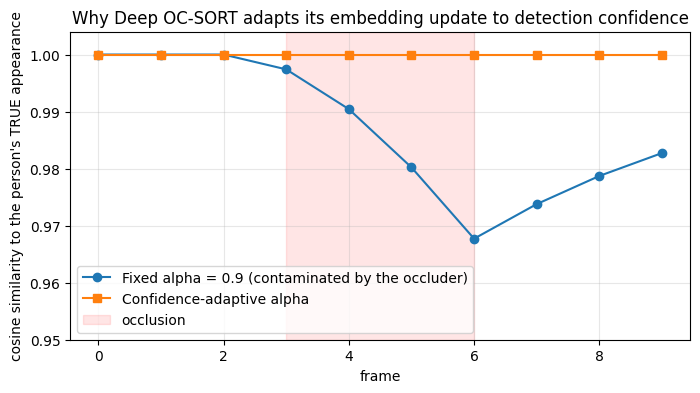

In [ ]:
# ── CONCEPT DEMO: Dynamic appearance EMA ────────────────────────────────────────────────────
def dynamic_alpha(det_conf, det_thresh=0.6, alpha_fixed=0.95):
    trust = np.clip((det_conf - det_thresh) / (1.0 - det_thresh), 0.0, 1.0)     # 1 = fully trusted detection
    return alpha_fixed + (1.0 - alpha_fixed) * (1.0 - trust)

def ema_update(track_emb, det_emb, alpha):
    e = alpha * track_emb + (1.0 - alpha) * det_emb
    return e / np.linalg.norm(e)

rng = np.random.default_rng(7)
true_emb = rng.normal(size=64); true_emb /= np.linalg.norm(true_emb)             # what this person REALLY looks like
occluder = rng.normal(size=64); occluder /= np.linalg.norm(occluder)             # the thing standing in front of them

print("conf -> alpha (how strongly the OLD embedding is kept)")
for c in (0.95, 0.8, 0.65, 0.5, 0.3):
    print(f"  conf {c:.2f} -> alpha {dynamic_alpha(c):.3f}")

# A run of 10 frames: the person is occluded in frames 3-6 -> detections are low-confidence AND contaminated
frames_conf  = [0.95, 0.93, 0.9, 0.45, 0.4, 0.4, 0.45, 0.9, 0.93, 0.95]
frames_embed = [true_emb if not (3 <= i <= 6) else (0.5 * true_emb + 0.5 * occluder) for i in range(10)]
frames_embed = [e / np.linalg.norm(e) for e in frames_embed]

fixed_track, dyn_track = true_emb.copy(), true_emb.copy()
hist_fixed, hist_dyn = [], []
for conf, e in zip(frames_conf, frames_embed):
    fixed_track = ema_update(fixed_track, e, alpha=0.9)                     # naive: constant EMA
    dyn_track   = ema_update(dyn_track,  e, alpha=dynamic_alpha(conf, alpha_fixed=0.9))   # same base alpha, confidence-adaptive
    hist_fixed.append(fixed_track @ true_emb); hist_dyn.append(dyn_track @ true_emb)

plt.figure(figsize=(8, 4))
plt.plot(hist_fixed, "o-", label="Fixed alpha = 0.9 (contaminated by the occluder)")
plt.plot(hist_dyn,   "s-", label="Confidence-adaptive alpha")
plt.axvspan(3, 6, color="red", alpha=0.1, label="occlusion")
plt.ylim(0.95, 1.004); plt.xlabel("frame"); plt.ylabel("cosine similarity to the person's TRUE appearance")
plt.title("Why Deep OC-SORT adapts its embedding update to detection confidence")   # trade-off: it also adapts slowly to REAL appearance change
plt.legend(loc="lower left"); plt.grid(alpha=.3); plt.show()

In [ ]:
# ── REAL Deep OC-SORT with Ultralytics ──────────────────────────────────────────────────────
# Defaults: motion-only + gmc_method "none". Customised ReID / camera-motion variants are built in Day 32.
model = YOLO(MODEL_WEIGHTS)
results = model.track(
    source=VIDEO_PATH,
    tracker="deepocsort.yaml",
    classes=[0], conf=0.25,
    save=True, project=str(OUT_DIR), name="deepocsort_default", exist_ok=True, verbose=False,
)
print("Saved to:", OUT_DIR / "deepocsort_default")

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /home/norbert/Projects/computer_vision_oly/object_tracking/runs/detect/data/videos/deepocsort_default
Saved to: data/videos/deepocsort_default


## Day 30 — FastTracker: Occlusion-Aware ByteTrack

**Topics:** Occlusion detection by coverage, Kalman rollback, motion dampening, search expansion, init-IoU suppression

FastTracker is an **occlusion-aware ByteTrack variant with no appearance model**. It starts from ByteTrack's cheap association and adds a small set of tricks that all fire **only when targets overlap**:

1. **Occlusion detection.** A track is flagged *occluded* when the fraction of its area **covered by other active tracks** exceeds `occ_cover_thresh`.
2. **Kalman rollback on occlusion.** When occlusion begins, the filter state is **rolled back** to a frame *before* the overlap (using a ring buffer of past states). Why? During the overlap the detector's box for the hidden person is corrupted — it shrinks, shifts toward the occluder, or merges — and the Kalman filter has been learning from that garbage. Rolling back discards the contaminated updates.
3. **Motion dampening and search expansion.** While occluded, the velocity is **multiplied by a damping factor** (the track "slows down", since you are unsure of it) and the predicted box is **enlarged** so that the re-appearing detection still lands inside the search region.
4. **Init-IoU suppression.** A new detection that overlaps an **active** track by more than `init_iou_suppress` is *not allowed to spawn a new track* — it is almost certainly the same person with a messy box. This kills **duplicate IDs** around overlaps.

**Best for:** real-time, detection-only pipelines with **frequent target-on-target overlap** (crowds, queues, sports).

### FastTracker-specific arguments
| Parameter | Valid values | Description |
|---|---|---|
| `reset_velocity_offset_occ` | ≥ 0 | History frames back to restore Kalman **velocity** on occlusion onset. |
| `reset_pos_offset_occ` | ≥ 0 | History frames back to restore Kalman **position** on occlusion onset. |
| `enlarge_bbox_occ` | ≥ 1.0 | Height scaling applied to the predicted bbox while occluded (width scales via the XYAH aspect ratio). |
| `dampen_motion_occ` | 0.0 – 1.0 | Velocity multiplier while occluded. **Lower values make the track "slow down" through occlusion.** |
| `active_occ_to_lost_thresh` | ≥ 1 | Max consecutive occluded frames before an *active* track is moved to *lost*. |
| `occ_cover_thresh` | 0.0 – 1.0 | Fraction of a track's area covered by another active track to declare occlusion. |
| `occ_reappear_window` | ≥ 0 | Frames a recently-occluded *lost* track stays **preferentially re-findable**. |
| `init_iou_suppress` | 0.0 – 1.0 | Suppress new-track initialisation if its IoU with any active track exceeds this. **Set to `1.0` to disable.** |

### Tuning tips
* **Frequent partial occlusions** → lower `occ_cover_thresh` (e.g. `0.5–0.6`) so occlusion handling kicks in earlier.
* **Duplicate IDs around overlap** → lower `init_iou_suppress` (e.g. `0.5`).
* **Long occlusions** → raise `occ_reappear_window` **and** `track_buffer` *together* (one without the other is wasted).
* **Fast-moving targets** → raise `dampen_motion_occ` toward `1.0` (don't brake a fast mover); raise `enlarge_bbox_occ` *only* when a wider search region actually improves recovery — a huge search box invites wrong matches.

Coverage of the far person by the near person: 67%
  occ_cover_thresh = 0.7: occluded -> False
  occ_cover_thresh = 0.5: occluded -> True
  (a LOWER threshold declares occlusion earlier -> rollback / dampening / enlargement start sooner)
  dampen_motion_occ = 1.0: velocity while occluded = [6. 0.]
  dampen_motion_occ = 0.7: velocity while occluded = [4.2 0. ]
  dampen_motion_occ = 0.3: velocity while occluded = [1.8 0. ]
  enlarged search box (enlarge_bbox_occ=1.3): [91, 28, 169, 222]
  init_iou_suppress = 0.5: IoU(new det, active track) = 0.64 -> spawn new track? False
  init_iou_suppress = 0.8: IoU(new det, active track) = 0.64 -> spawn new track? True
  init_iou_suppress = 1.0: IoU(new det, active track) = 0.64 -> spawn new track? True


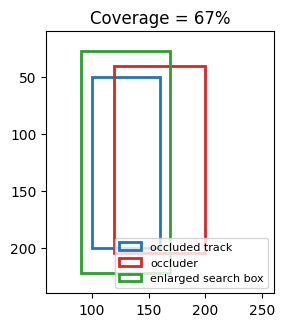

In [ ]:
# ── CONCEPT DEMO: occlusion coverage, dampened/enlarged prediction, init-IoU suppression ────
def coverage_fraction(box, others):
    """Fraction of `box` area covered by the UNION of `others` (pixel-mask based, so overlaps aren't double-counted)."""
    x1, y1, x2, y2 = [int(v) for v in box]
    mask = np.zeros((y2 - y1, x2 - x1), bool)
    for ox1, oy1, ox2, oy2 in others:
        ix1, iy1, ix2, iy2 = max(x1, int(ox1)), max(y1, int(oy1)), min(x2, int(ox2)), min(y2, int(oy2))
        if ix2 > ix1 and iy2 > iy1:
            mask[iy1 - y1:iy2 - y1, ix1 - x1:ix2 - x1] = True
    return float(mask.mean())

def enlarge_box(box, scale):
    """Scale height by `scale`; width follows because the aspect ratio (w/h) is kept (XYAH parametrisation)."""
    cx, cy, w, h = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2, box[2] - box[0], box[3] - box[1]
    w, h = w * scale, h * scale
    return [cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2]

person_far  = [100, 50, 160, 200]      # track being hidden
person_near = [120, 40, 200, 205]      # track walking in front of it
cover = coverage_fraction(person_far, [person_near])
print(f"Coverage of the far person by the near person: {cover:.0%}")
for thr in (0.7, 0.5):
    print(f"  occ_cover_thresh = {thr}: occluded -> {cover > thr}")
print("  (a LOWER threshold declares occlusion earlier -> rollback / dampening / enlargement start sooner)")

velocity = np.array([6.0, 0.0])
for damp in (1.0, 0.7, 0.3):
    print(f"  dampen_motion_occ = {damp}: velocity while occluded = {velocity * damp}")
print("  enlarged search box (enlarge_bbox_occ=1.3):", [round(v) for v in enlarge_box(person_far, 1.3)])

# init-IoU suppression: a messy second detection of an already-tracked person must not spawn a new ID
active_track = [300, 60, 360, 210]
new_det      = [310, 70, 372, 215]
iou_new = calculate_iou(active_track, new_det)
for supp in (0.5, 0.8, 1.0):
    print(f"  init_iou_suppress = {supp}: IoU(new det, active track) = {iou_new:.2f} -> spawn new track? {iou_new <= supp or supp >= 1.0}")

fig, ax = plt.subplots(figsize=(6, 3.4))
for b, c, l in [(person_far, "tab:blue", "occluded track"), (person_near, "tab:red", "occluder"),
                (enlarge_box(person_far, 1.3), "tab:green", "enlarged search box")]:
    ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec=c, lw=2, label=l))
ax.set_xlim(60, 260); ax.set_ylim(240, 10); ax.set_aspect("equal"); ax.legend(loc="lower right", fontsize=8)
ax.set_title(f"Coverage = {cover:.0%}"); plt.show()

In [ ]:
# ── REAL FastTracker with Ultralytics ───────────────────────────────────────────────────────
model = YOLO(MODEL_WEIGHTS)
results = model.track(
    source=VIDEO_PATH,
    tracker="fasttrack.yaml",
    classes=[0], conf=0.25,
    save=True, project=str(OUT_DIR), name="fasttrack_default", exist_ok=True, verbose=False,
)
print("Saved to:", OUT_DIR / "fasttrack_default")

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /home/norbert/Projects/computer_vision_oly/object_tracking/runs/detect/data/videos/fasttrack_default
Saved to: data/videos/fasttrack_default


## Day 31 — TrackTrack: Track-Perspective Multi-Cue Association

**Topics:** TPA, HMIoU, confidence-projection and corner-angle distances, iterative threshold relaxation, TAI, secondary NMS

TrackTrack (*Shim et al., CVPR 2025*) is the **default tracker**. Most trackers think *from the detection's perspective* ("which track does this box belong to?"). TrackTrack reasons **from each track's perspective** and combines several cues in an **iterative** association:

### Track-Perspective-Based Association (TPA)
The cost between a track and a detection is a **weighted sum of several distances**:
* **HMIoU** — *Height-Modulated IoU*: IoU multiplied by how well the **vertical extents** agree. Two boxes may have decent IoU while one is a head-and-shoulders crop of the other; vertical agreement penalises that.
* **Cosine ReID distance** — *optional* (`with_reid`). Appearance.
* **Confidence-projection distance** — roughly: compares the confidence the track "expects" with the detection's confidence, so a low-confidence flicker can't steal a track from a confident detection. *(Described conceptually — see the paper for the exact definition.)*
* **Corner-angle distance** — roughly: a *direction*-consistency cue computed from box corners, similar in spirit to OC-SORT's momentum. *(Again conceptual; see the paper.)*

Assignment is solved **iteratively with a relaxing threshold**: first only very confident, low-cost pairs are matched; then the threshold is relaxed by `reduce_step` and the *remaining* tracks/detections are matched again, and so on. "Easy" pairs are locked in first so that "hard" pairs cannot corrupt them — the same philosophy as ByteTrack's two stages, generalised to many rounds.

### Track-Aware Initialisation (TAI)
Before a new ID is created, unmatched detections are checked (NMS-style, at IoU `tai_thr`) against the **active tracks and against each other**. Duplicates are suppressed. This is TrackTrack's answer to the **duplicate-ID problem** in crowds. A *secondary NMS* also recovers detections that the detector's NMS removed wrongly in crowded areas (those get a cost penalty `penalty_q`).

**Best for:** crowded scenes with frequent occlusion where duplicate IDs are a problem.

### TrackTrack-specific arguments
| Parameter | Valid values | Description |
|---|---|---|
| `iou_weight` | 0.0 – 1.0 | Weight of HMIoU distance when ReID is enabled; otherwise HMIoU is used directly. |
| `reid_weight` | 0.0 – 1.0 | Weight of cosine ReID distance when ReID is enabled; otherwise it is ignored. |
| `conf_weight` | 0.0 – 1.0 | Weight of confidence-projection distance. |
| `angle_weight` | 0.0 – 1.0 | Weight of corner-angle distance. |
| `penalty_p` | 0.0 – 1.0 | Cost penalty for low-confidence detections. |
| `penalty_q` | 0.0 – 1.0 | Cost penalty for detections recovered by secondary NMS. |
| `reduce_step` | 0.0 – 1.0 | Match-threshold relaxation per iteration. |
| `tai_thr` | 0.0 – 1.0 | IoU threshold for Track-Aware Initialisation NMS. |
| `min_track_len` | ≥ 0 | Minimum history length before a new track is confirmed. |
| `lost_match_thr` | 0.0 – 1.0 | Looser cost gate for the relaxed lost-rebind pass; `0` disables it. |
| `with_reid` | `True`, `False` | Enable cosine-ReID appearance matching (uses native YOLO features). Off by default. |
| `model` | `auto` or ReID model path | `auto` uses native YOLO features when available. |
| `gmc_method` | `sparseOptFlow`, `orb`, `sift`, `ecc`, `none` | Global motion compensation method. |

### Tuning tips
* **Crowded pedestrians** → lower `tai_thr` (e.g. `0.45`) to suppress more duplicate spawns; raise `track_buffer` for longer occlusions.
* **Fast camera motion** → keep `gmc_method: sparseOptFlow` enabled.
* **Small / fast objects** → raise `angle_weight` slightly and lower `min_track_len`.
* **Enable ReID only when needed** → it adds inference cost; for short occlusions the default multi-cue cost is usually sufficient.

> **Segment & Pose models.** With segmentation and pose models TrackTrack **skips loose-NMS detection recovery** so masks and keypoints stay aligned with their detections.

Three small simulations follow: HMIoU, iterative threshold relaxation, and TAI. They are **simplified illustrations** of the ideas (the confidence/angle cues are omitted here).

In [ ]:
# ── CONCEPT DEMO 1: HMIoU — IoU modulated by vertical agreement ─────────────────────────────
def hmiou(a, b):
    iou = calculate_iou(a, b)
    inter_h = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    union_h = max(a[3], b[3]) - min(a[1], b[1])
    return iou * (inter_h / union_h if union_h > 0 else 0.0)

track_box = [100, 100, 160, 260]                          # full-body person
candidates = {
    "Same person, slightly shifted":  [108, 104, 168, 266],
    "Torso-only crop (same x-range)": [100, 100, 160, 180],
    "Neighbour, same height":         [150, 100, 210, 260],
}
print(f"{'candidate':<34}{'IoU':>7}{'HMIoU':>9}")
for name, c in candidates.items():
    print(f"{name:<34}{calculate_iou(track_box, c):>7.2f}{hmiou(track_box, c):>9.2f}")

candidate                             IoU    HMIoU
Same person, slightly shifted        0.72     0.68
Torso-only crop (same x-range)       0.50     0.25
Neighbour, same height               0.09     0.09


In [ ]:
# ── CONCEPT DEMO 2: iterative association with a relaxing threshold ─────────────────────────
def iterative_association(cost, start_thr=0.3, reduce_step=0.15, max_thr=0.75):
    """Match the most trustworthy pairs first, then relax the cost gate and match what is left."""
    cost = np.asarray(cost, float)
    rows, cols, matches, log, thr = list(range(cost.shape[0])), list(range(cost.shape[1])), [], [], start_thr
    while rows and cols and thr <= max_thr + 1e-9:
        sub = cost[np.ix_(rows, cols)]
        r, c = linear_sum_assignment(sub)
        newly = [(rows[i], cols[j]) for i, j in zip(r, c) if sub[i, j] <= thr]
        matches += newly
        rows = [x for x in rows if x not in {t for t, _ in newly}]
        cols = [x for x in cols if x not in {d for _, d in newly}]
        log.append((round(thr, 2), newly))
        thr += reduce_step
    return matches, rows, cols, log

# 3 tracks x 4 detections (cost = 1 - similarity). Track 2 moved fast, so its true match is poor (0.62).
cost = np.array([[0.10, 0.80, 0.90, 0.85],
                 [0.75, 0.28, 0.80, 0.90],
                 [0.90, 0.85, 0.62, 0.70]])
matches, left_t, left_d, log = iterative_association(cost)
for thr, newly in log:
    print(f"gate <= {thr:.2f}: newly matched {newly}")
print("final matches:", matches, "| unmatched tracks:", left_t, "| unmatched detections (-> candidates for new tracks):", left_d)

# Compare with a single strict gate: the fast-moving track 2 would be lost
r, c = linear_sum_assignment(cost)
print("\nSingle strict gate (<= 0.3):", [(int(t), int(d)) for t, d in zip(r, c) if cost[t, d] <= 0.3])

gate <= 0.30: newly matched [(0, 0), (1, 1)]
gate <= 0.45: newly matched []
gate <= 0.60: newly matched []
gate <= 0.75: newly matched [(2, 2)]
final matches: [(0, 0), (1, 1), (2, 2)] | unmatched tracks: [] | unmatched detections (-> candidates for new tracks): [3]

Single strict gate (<= 0.3): [(0, 0), (1, 1)]


In [ ]:
# ── CONCEPT DEMO 3: Track-Aware Initialisation (TAI) ───────────────────────────────────────
def track_aware_init(det_boxes, det_scores, track_boxes, tai_thr=0.55):
    """Return indices of unmatched detections allowed to start NEW tracks (NMS vs tracks AND vs each other)."""
    keep = []
    for i in np.argsort(-np.asarray(det_scores)):                 # best detections first
        if any(calculate_iou(det_boxes[i], t) > tai_thr for t in track_boxes):  continue   # duplicate of an existing track
        if any(calculate_iou(det_boxes[i], det_boxes[k]) > tai_thr for k in keep): continue  # duplicate of another new det
        keep.append(int(i))
    return sorted(keep)

active_tracks = [[100, 100, 160, 260], [300, 90, 360, 250]]
unmatched_dets = [[112, 104, 174, 264],    # 0: duplicate of track 0 (messy second box, IoU ~0.6)
                  [500, 100, 560, 260],    # 1: genuinely new person
                  [518, 110, 579, 270],    # 2: duplicate of 1 (lower score, IoU ~0.48)
                  [30, 120, 80, 250]]      # 3: genuinely new person
scores = [0.82, 0.90, 0.60, 0.75]

for thr in (0.8, 0.55, 0.45):
    print(f"tai_thr = {thr}: detections allowed to spawn a new ID -> {track_aware_init(unmatched_dets, scores, active_tracks, thr)}")
print("Truth: only detections 1 and 3 are new people. A permissive (high) tai_thr lets duplicates through -> duplicate IDs;")
print("lowering it suppresses progressively milder duplicates (but too low can suppress real, closely-standing people!).")

tai_thr = 0.8: detections allowed to spawn a new ID -> [0, 1, 2, 3]
tai_thr = 0.55: detections allowed to spawn a new ID -> [1, 2, 3]
tai_thr = 0.45: detections allowed to spawn a new ID -> [1, 3]
Truth: only detections 1 and 3 are new people. A permissive (high) tai_thr lets duplicates through -> duplicate IDs;
lowering it suppresses progressively milder duplicates (but too low can suppress real, closely-standing people!).


In [ ]:
# ── REAL TrackTrack with Ultralytics (the default tracker) ──────────────────────────────────
model = YOLO(MODEL_WEIGHTS)
results = model.track(
    source=VIDEO_PATH,
    tracker="tracktrack.yaml",          # same as omitting `tracker=` in recent Ultralytics versions
    classes=[0], conf=0.25,
    save=True, project=str(OUT_DIR), name="tracktrack_default", exist_ok=True, verbose=False,
)
print("Saved to:", OUT_DIR / "tracktrack_default")

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs



RuntimeError: 
  #ifdef __HIPCC__
  #define ERROR_UNSUPPORTED_CAST ;
  // corresponds to aten/src/ATen/native/cuda/thread_constants.h
  #define CUDA_OR_ROCM_NUM_THREADS 256
  // corresponds to aten/src/ATen/cuda/detail/OffsetCalculator.cuh
  #define MAX_DIMS 16
  #ifndef __forceinline__
  #define __forceinline__ inline __attribute__((always_inline))
  #endif
  #else
  #define ERROR_UNSUPPORTED_CAST __trap();
  #define CUDA_OR_ROCM_NUM_THREADS 128
  #define MAX_DIMS 25
  #endif
  #define POS_INFINITY __int_as_float(0x7f800000)
  #define INFINITY POS_INFINITY
  #define NEG_INFINITY __int_as_float(0xff800000)
  #define NAN __int_as_float(0x7fffffff)

  typedef long long int int64_t;
  typedef unsigned int uint32_t;
  typedef signed char int8_t;
  typedef unsigned char uint8_t;  // NOTE: this MUST be "unsigned char"! "char" is equivalent to "signed char"
  typedef short int16_t;
  typedef unsigned short uint16_t;
  typedef unsigned long long uint64_t;
  static_assert(sizeof(int64_t) == 8, 

## Day 32 — Customising Tracker YAML Files & Benchmarking

**Topics:** Reading the shipped YAML, overriding parameters safely, parameter sweeps, per-scenario presets

Every `*.yaml` file is just a dictionary of hyper-parameters. The workflow for tuning is always the same:

1. **Load** the default YAML that ships with your Ultralytics install (so you start from the exact version you run).
2. **Override** only the keys you want to change.
3. **Save** it as a new file and pass its path to `tracker=`.
4. **Measure** (proxy statistics from Day 25 → real metrics from Day 36) — never tune by eyeballing a single clip.

The helper below *refuses unknown keys*. A typo such as `track_bufer: 90` would otherwise be silently ignored and you would "tune" for an hour with no effect.

> **Frame-rate warning.** `track_buffer` is measured in **frames**. A buffer of 30 is one second at 30 FPS but only half a second at 60 FPS and three seconds at 10 FPS. Scale it with your video's FPS.

In [ ]:
from ultralytics.utils import ROOT

def load_default_tracker_cfg(name):
    """Load the YAML that ships with the installed ultralytics (name without extension, e.g. 'botsort')."""
    path = ROOT / "cfg" / "trackers" / f"{name}.yaml"
    return yaml.safe_load(path.read_text()), path

def make_tracker_cfg(base_name, out_name, **overrides):
    """Copy a default tracker YAML, apply overrides (unknown keys raise), save, and return the file path."""
    cfg, _ = load_default_tracker_cfg(base_name)
    unknown = set(overrides) - set(cfg)
    if unknown:
        raise KeyError(f"Unknown keys for {base_name}.yaml: {sorted(unknown)}. Valid keys: {sorted(cfg)}")
    cfg.update(overrides)
    out_path = OUT_DIR / f"{out_name}.yaml"
    out_path.write_text(yaml.safe_dump(cfg, sort_keys=False))
    return str(out_path)

# Look at what ships with YOUR version (parameters and defaults differ slightly between releases)
for name in ("botsort", "bytetrack", "ocsort", "deepocsort", "fasttrack", "tracktrack"):
    cfg, path = load_default_tracker_cfg(name)
    print(f"── {name}.yaml ({len(cfg)} keys)")
    print(yaml.safe_dump(cfg, sort_keys=False))

── botsort.yaml (12 keys)
tracker_type: botsort
track_high_thresh: 0.25
track_low_thresh: 0.1
new_track_thresh: 0.25
track_buffer: 30
match_thresh: 0.8
fuse_score: true
gmc_method: sparseOptFlow
proximity_thresh: 0.5
appearance_thresh: 0.8
with_reid: false
model: auto

── bytetrack.yaml (7 keys)
tracker_type: bytetrack
track_high_thresh: 0.25
track_low_thresh: 0.1
new_track_thresh: 0.25
track_buffer: 30
match_thresh: 0.8
fuse_score: true

── ocsort.yaml (10 keys)
tracker_type: ocsort
track_high_thresh: 0.25
track_low_thresh: 0.1
new_track_thresh: 0.25
track_buffer: 30
match_thresh: 0.8
fuse_score: true
delta_t: 3
inertia: 0.2
use_byte: false

── deepocsort.yaml (16 keys)
tracker_type: deepocsort
track_high_thresh: 0.3
track_low_thresh: 0.1
new_track_thresh: 0.3
track_buffer: 30
match_thresh: 0.8
fuse_score: true
delta_t: 3
inertia: 0.2
use_byte: false
gmc_method: none
with_reid: false
model: auto
proximity_thresh: 0.5
appearance_thresh: 0.9
alpha_fixed_emb: 0.95

── fasttrack.yaml (15 

### Scenario presets (straight from the tuning tips)
Each preset encodes one tip from the tracker sections above. The numbers are **starting points**, not magic constants.

| Preset | Base | Overrides | Why |
|---|---|---|---|
| `botsort_static_cam` | BoT-SORT | `gmc_method: none` | Static camera: skip CMC, save ms/frame. |
| `botsort_lookalike` | BoT-SORT | `with_reid: True`, `appearance_thresh: 0.85` | Look-alike crowd: appearance on, strict. |
| `ocsort_nonlinear` | OC-SORT | `inertia: 0.35`, `use_byte: True`, `track_buffer: 60` | Abrupt turns, sparse detections, long occlusions. |
| `deepocsort_crowd` | Deep OC-SORT | `with_reid: True`, `appearance_thresh: 0.93`, `alpha_fixed_emb: 0.97`, `gmc_method: sparseOptFlow` | Fewer swaps in crowds + moving camera. |
| `fasttrack_queue` | FastTracker | `occ_cover_thresh: 0.55`, `init_iou_suppress: 0.5`, `occ_reappear_window` & `track_buffer` raised together | Frequent overlap, duplicate IDs. |
| `tracktrack_crowd` | TrackTrack | `tai_thr: 0.45`, `track_buffer: 60` | Crowded pedestrians, longer occlusions. |

In [ ]:
PRESETS = {
    "botsort_static_cam": make_tracker_cfg("botsort", "botsort_static_cam", gmc_method="none"),
    "botsort_lookalike":  make_tracker_cfg("botsort", "botsort_lookalike", with_reid=True, appearance_thresh=0.85),
    "ocsort_nonlinear":   make_tracker_cfg("ocsort", "ocsort_nonlinear", inertia=0.35, use_byte=True, track_buffer=60),
    "deepocsort_crowd":   make_tracker_cfg("deepocsort", "deepocsort_crowd", with_reid=True, appearance_thresh=0.93,
                                           alpha_fixed_emb=0.97, gmc_method="sparseOptFlow"),
    "fasttrack_queue":    make_tracker_cfg("fasttrack", "fasttrack_queue", occ_cover_thresh=0.55, init_iou_suppress=0.5,
                                           occ_reappear_window=45, track_buffer=60),
    "tracktrack_crowd":   make_tracker_cfg("tracktrack", "tracktrack_crowd", tai_thr=0.45, track_buffer=60),
}
for k, v in PRESETS.items():
    print(f"{k:<20} -> {v}")

# Use one exactly like a built-in tracker:
model = YOLO(MODEL_WEIGHTS)
results = model.track(source=VIDEO_PATH, tracker=PRESETS["tracktrack_crowd"], classes=[0], conf=0.25, verbose=False)

botsort_static_cam   -> data/videos/botsort_static_cam.yaml
botsort_lookalike    -> data/videos/botsort_lookalike.yaml
ocsort_nonlinear     -> data/videos/ocsort_nonlinear.yaml
deepocsort_crowd     -> data/videos/deepocsort_crowd.yaml
fasttrack_queue      -> data/videos/fasttrack_queue.yaml
tracktrack_crowd     -> data/videos/tracktrack_crowd.yaml
WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs



RuntimeError: 
  #ifdef __HIPCC__
  #define ERROR_UNSUPPORTED_CAST ;
  // corresponds to aten/src/ATen/native/cuda/thread_constants.h
  #define CUDA_OR_ROCM_NUM_THREADS 256
  // corresponds to aten/src/ATen/cuda/detail/OffsetCalculator.cuh
  #define MAX_DIMS 16
  #ifndef __forceinline__
  #define __forceinline__ inline __attribute__((always_inline))
  #endif
  #else
  #define ERROR_UNSUPPORTED_CAST __trap();
  #define CUDA_OR_ROCM_NUM_THREADS 128
  #define MAX_DIMS 25
  #endif
  #define POS_INFINITY __int_as_float(0x7f800000)
  #define INFINITY POS_INFINITY
  #define NEG_INFINITY __int_as_float(0xff800000)
  #define NAN __int_as_float(0x7fffffff)

  typedef long long int int64_t;
  typedef unsigned int uint32_t;
  typedef signed char int8_t;
  typedef unsigned char uint8_t;  // NOTE: this MUST be "unsigned char"! "char" is equivalent to "signed char"
  typedef short int16_t;
  typedef unsigned short uint16_t;
  typedef unsigned long long uint64_t;
  static_assert(sizeof(int64_t) == 8, 

### Parameter sweep: how much memory (`track_buffer`) does a tracker need?
A sweep over **one** parameter, plotted against the proxy statistics, teaches more than any rule of thumb. Expect:
* **Too small** a buffer → tracks die during short occlusions → *many unique IDs, short tracks* (fragmentation).
* **Too large** a buffer → dead tracks linger and may be wrongly "revived" by a different person → ID swaps that the proxy statistics *cannot* show you. That is why a sweep must end with **ground-truth metrics** (Day 36) wherever possible.

,unique_ids,mean_track_len,median_track_len,short_tracks_lt10,tracks_with_gaps,avg_people_per_frame
track_buffer,,,,,,
5,1,50.0,50.0,0,0,0.33
15,1,50.0,50.0,0,0,0.33
30,1,50.0,50.0,0,0,0.33
60,1,50.0,50.0,0,0,0.33
120,1,50.0,50.0,0,0,0.33


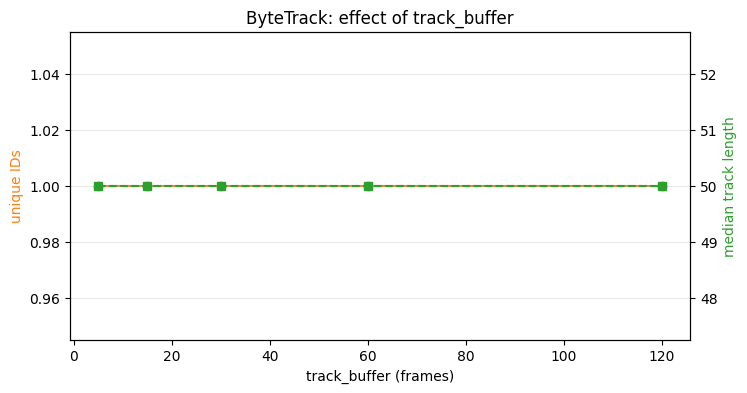

In [ ]:
buffers, sweep_rows = [5, 15, 30, 60, 120], []
for b in buffers:
    cfg_path = make_tracker_cfg("bytetrack", f"bytetrack_buf{b}", track_buffer=b)
    ids, secs = run_tracker(cfg_path, max_frames=150)
    s = summarize_ids(ids); s["track_buffer"] = b
    sweep_rows.append(s)

df_sweep = pd.DataFrame(sweep_rows).set_index("track_buffer")
display(df_sweep)

fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(df_sweep.index, df_sweep["unique_ids"], "o-", color="tab:orange", label="unique IDs")
ax1.set_xlabel("track_buffer (frames)"); ax1.set_ylabel("unique IDs", color="tab:orange")
ax2 = ax1.twinx(); ax2.plot(df_sweep.index, df_sweep["median_track_len"], "s--", color="tab:green", label="median track length")
ax2.set_ylabel("median track length", color="tab:green")
plt.title("ByteTrack: effect of track_buffer"); plt.grid(alpha=.3); plt.show()

## Day 33 — Drawing Trajectories (Track Trails)

**Topics:** Per-ID history, polylines, colour per identity, memory hygiene

A **track trail** is the line each object has recently travelled. It is the quickest way to *visually debug* a tracker: a smooth continuous coloured trail means a stable identity; a trail that suddenly changes colour or jumps to another person is an ID switch you can **see**.

Recipe (from the Ultralytics docs, adapted for a notebook):

1. Run `model.track(frame, persist=True)` per frame (we own the loop → `persist=True`).
2. Guard with `result.boxes.is_track` before reading IDs.
3. Take the **centre points** (`boxes.xywh`) and append `(x, y)` to a `defaultdict(list)` keyed by track ID.
4. **Cap the history** (e.g. 30 points) so trails fade instead of growing forever.
5. Draw each history with `cv2.polylines`.

Differences from the minimal docs snippet and *why*:
* **No `cv2.imshow`** — it needs a GUI and hangs in headless notebooks/servers. We write a video file and show preview frames inline instead.
* **Thinner lines, one colour per ID** — thickness 10 in a single grey hides the scene, and one colour makes identity swaps invisible.
* **Pruning** — `track_history` otherwise keeps every ID ever seen; in a long video that is a slow memory leak. We drop histories not updated recently.

In [ ]:
def id_color(track_id):
    """Deterministic, bright colour per ID so the same identity always has the same colour."""
    rng = np.random.default_rng(int(track_id))
    return tuple(int(c) for c in rng.integers(60, 255, 3))

def track_and_draw(video, tracker="bytetrack.yaml", out_path=OUT_DIR / "trails.mp4",
                   weights=MODEL_WEIGHTS, max_frames=150, trail_len=30, classes=(0,), conf=0.25, preview_every=30):
    cap = cv2.VideoCapture(str(video))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    writer = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

    model = YOLO(weights)
    history, last_seen, previews, n = defaultdict(list), {}, [], 0
    while cap.isOpened() and n < max_frames:
        ok, frame = cap.read()
        if not ok:
            break
        result = model.track(frame, persist=True, tracker=tracker, classes=list(classes), conf=conf, verbose=False)[0]
        frame = result.plot()                                              # boxes + "id:" labels

        if result.boxes.is_track:                                          # guard: .id is None otherwise
            centres = result.boxes.xywh.cpu().tolist()
            ids = result.boxes.id.int().cpu().tolist()
            for (x, y, _, _), tid in zip(centres, ids):
                trail = history[tid]; trail.append((x, y)); del trail[:-trail_len]     # keep last `trail_len` points
                last_seen[tid] = n
                if len(trail) > 1:
                    pts = np.array(trail, dtype=np.int32).reshape(-1, 1, 2)
                    cv2.polylines(frame, [pts], isClosed=False, color=id_color(tid), thickness=3)

        for tid in [t for t, last in last_seen.items() if n - last > trail_len]:      # prune stale IDs
            history.pop(tid, None); last_seen.pop(tid, None)

        writer.write(frame)
        if n % preview_every == 0:
            previews.append(frame.copy())
        n += 1
    cap.release(); writer.release()
    print(f"Wrote {n} frames to {out_path}")
    return previews

previews = track_and_draw(VIDEO_PATH, tracker="bytetrack.yaml")
show_frames(previews, [f"frame {i * 30}" for i in range(len(previews))], cols=min(4, len(previews)))

## Day 34 — Multithreaded Tracking (several streams at once)

**Topics:** One model per thread, `daemon` threads, `stream=True`, when threads help (and when they don't)

Real deployments rarely have a single camera. The docs' pattern is to run **one tracker per thread**, each with **its own model object** and its own source.

### Rules that prevent subtle bugs
1. **Create the `YOLO(...)` object *inside* the thread.** A model carries its tracker's state (`persist` memory). Sharing one model between two streams would mix their tracks and the IDs would cross-contaminate.
2. **Use `stream=True`** and *consume* the generator (`for r in results: pass` or process each `r`). Without iteration nothing runs; without `stream=True` all frames are accumulated in RAM.
3. **`daemon=True`** lets the interpreter exit even if a thread is stuck on a dead camera; **always `join()`** the threads you want to wait for.
4. **Threads ≠ more GPU.** Python threads overlap I/O and GPU kernels well, but two models still share one GPU. For many streams, batch inputs or use separate processes/GPUs.
5. **Webcam sources are strings.** `"0"` in `source` (as in the snippet below) means camera index 0.
6. **Avoid `cv2.imshow` from worker threads** — GUI calls belong to the main thread (and don't work headless anyway). We collect results into a dict instead.

In [ ]:
# Define model names and video sources (one model per source; the two lists are paired with zip)
MODEL_NAMES = [MODEL_WEIGHTS, MODEL_WEIGHTS.replace(".pt", "-seg.pt")]        # detection model, segmentation model
SOURCES     = [VIDEO_PATH, VIDEO_PATH]                                       # use "0" instead of a path for a webcam

thread_results = {}                                                          # filled by the workers

def run_tracker_in_thread(model_name, filename, tracker="bytetrack.yaml"):
    """Run a YOLO tracker in its own thread for concurrent processing.

    Args:
        model_name (str): Model checkpoint loaded INSIDE the thread (private tracker state).
        filename (str): Video path, URL, or "0" for the default webcam.
    """
    model = YOLO(model_name)
    unique_ids, frames = set(), 0
    for r in model.track(filename, tracker=tracker, save=True, stream=True, verbose=False,
                         project=str(OUT_DIR), name=f"thread_{Path(model_name).stem}", exist_ok=True):
        frames += 1
        if r.boxes.is_track:
            unique_ids.update(r.boxes.id.int().tolist())
    thread_results[model_name] = dict(frames=frames, unique_ids=len(unique_ids))

# Create and start tracker threads using a for loop
tracker_threads = []
for model_name, source in zip(MODEL_NAMES, SOURCES):
    thread = threading.Thread(target=run_tracker_in_thread, args=(model_name, source), daemon=True)
    tracker_threads.append(thread)
    thread.start()

# Wait for all tracker threads to finish
for thread in tracker_threads:
    thread.join()

print(thread_results)
cv2.destroyAllWindows()      # harmless if no windows are open; needed if you ever call show=True

## Day 35 — Classic OpenCV Trackers (Single-Object Tracking)

**Topics:** SOT vs MOT, the eight classic OpenCV trackers, version differences (`cv2.legacy`), benchmarking on a synthetic clip

Everything so far was **multi-object tracking by detection** (MOT): a detector finds *all* objects in *every* frame, the tracker only links them over time. OpenCV also ships **single-object trackers (SOT)** that work in the opposite way: *you* give one bounding box in the first frame (by hand with `cv2.selectROI`, or from a detector) and the tracker follows **that one appearance** through the following frames **without running a detector**.

| | MOT by detection (SORT, ByteTrack, …) | OpenCV SOT (KCF, CSRT, …) |
|---|---|---|
| Needs a detector every frame | **Yes** | **No** (only for the first box) |
| Number of objects | Many, new ones appear automatically | One tracker object per target |
| Recovers when the target reappears | Via association / ReID | Usually **not**, it just drifts or reports failure |
| Cost | Detector + tracker | Very cheap per object |
| Typical use | Analytics, counting | Follow-a-selected-object, speed-ups between detections |

### The eight classic OpenCV tracker classes
| # | Tracker | Core idea | Notes (speed / accuracy / behaviour) |
|---|---|---|---|
| 1 | **BOOSTING** | Online AdaBoost classifier trained on the first box (positive) vs. surroundings (negative) | Oldest (2006), **slow and inaccurate** by today's standards; mostly historical. Does not report failure reliably. |
| 2 | **MIL** (Multiple Instance Learning) | Like Boosting, but trains on *bags* of positive samples around the box | Better than BOOSTING, fairly good accuracy, but poor failure reporting. |
| 3 | **KCF** (Kernelized Correlation Filter) | Correlation filter in the Fourier domain with kernel trick | **Fast and accurate** on easy clips; **does not recover from full occlusion**. |
| 4 | **CSRT** (Discriminative Correlation Filter with Channel and Spatial Reliability; written "CRST" by mistake in many notes) | KCF-style filter + spatial reliability map (handles non-rectangular targets) + colour/HOG features | **Most accurate of the classic correlation-filter trackers, but slower** than KCF. A good default when accuracy matters. |
| 5 | **TLD** (Tracking-Learning-Detection) | Tracker + detector + online learning that corrects itself | **Tends to recover from occlusions** (it re-detects the target) — but is prone to **false positives** and jittery boxes. |
| 6 | **MEDIANFLOW** | Forward-backward optical-flow consistency check | **Good for predictable, slow motion**; reports failure well; fails on fast motion or large appearance change. |
| 7 | **GOTURN** | **Deep-learning** (CNN regressing the new box from the previous crop) | The only DNN one in the classic set. Needs **model files** (`goturn.prototxt` + `goturn.caffemodel`) in the working directory. Reasonably robust to viewpoint/lighting change but **not** generally the most accurate; not GPU-fast in OpenCV. |
| 8 | **MOSSE** (Minimum Output Sum of Squared Error) | Very simple adaptive correlation filter | **Fastest**; lower accuracy than KCF/CSRT; excellent when CPU budget is tiny. |

> **Quick selection rule.** Accuracy first → **CSRT**. Speed first → **MOSSE**. Balanced → **KCF**. Occlusion-prone and you can accept noise → **TLD**. Slow, predictable motion → **MEDIANFLOW**. Prefer a modern DNN → look at OpenCV's newer **`TrackerNano`**, **`TrackerVit`** and **`TrackerDaSiamRPN`** (they need ONNX model files; see the OpenCV docs), or simply use YOLO tracking from Parts I–II.

> **Version note.** Since OpenCV 4.5.1 several of these classes (BOOSTING, TLD, MEDIANFLOW, MOSSE) live in `cv2.legacy` (requires `opencv-contrib-python`), while MIL, KCF, CSRT and GOTURN live in `cv2`. The factory below tries both so the same notebook runs on any 4.x install.

### Typical usage pattern
```python
tracker = cv2.TrackerCSRT_create()          # 1. create
tracker.init(first_frame, (x, y, w, h))     # 2. init with a box in (x, y, WIDTH, HEIGHT) format!
ok, box = tracker.update(next_frame)        # 3. update every frame -> (success_flag, box)
```
Watch the **box format**: OpenCV trackers use `(x, y, w, h)`; YOLO and the rest of this notebook use `[x1, y1, x2, y2]`.

In [ ]:
CV_TRACKER_FACTORIES = {
    "BOOSTING":   "TrackerBoosting_create",
    "MIL":        "TrackerMIL_create",
    "KCF":        "TrackerKCF_create",
    "CSRT":       "TrackerCSRT_create",
    "TLD":        "TrackerTLD_create",
    "MEDIANFLOW": "TrackerMedianFlow_create",
    "GOTURN":     "TrackerGOTURN_create",
    "MOSSE":      "TrackerMOSSE_create",
}

def create_cv_tracker(name):
    """Create an OpenCV tracker by name, searching both `cv2` and `cv2.legacy`. Returns None if unavailable."""
    fn_name = CV_TRACKER_FACTORIES[name]
    for namespace in (cv2, getattr(cv2, "legacy", None)):
        if namespace is not None and hasattr(namespace, fn_name):
            try:
                return getattr(namespace, fn_name)()
            except cv2.error:
                return None            # e.g. GOTURN without its .prototxt/.caffemodel files
    return None

print("Availability in this OpenCV build (version", cv2.__version__ + "):")
for n in CV_TRACKER_FACTORIES:
    print(f"  {n:<11} -> {'available' if create_cv_tracker(n) is not None else 'NOT available (missing contrib module / model files)'}")

### A fair benchmark on a synthetic clip
We generate a clip where a **textured rectangle** moves along a smooth path across a cluttered background, and a **vertical bar passes in front of it** for some frames (a full occlusion). Because we draw it ourselves we know the **exact ground-truth box in every frame**, so we can compute per-frame IoU for each tracker, plus FPS.

Questions to answer while reading the results:
* Which trackers are fastest? (correlation-filter trackers such as MOSSE and KCF are usually far ahead of MIL or CSRT)
* Which survive the occlusion — meaning IoU recovers **after** the bar has passed? Look at the `iou_after_occlusion` column.
* Which *report* the failure (`ok=False`, see `reported_failures`) vs. confidently keep outputting a wrong box?

The numbers depend on your OpenCV build and CPU; treat them as a demonstration of the **method**, not as a verdict.

In [ ]:
def make_tracking_clip(n_frames=120, size=(360, 480), occlusion=(55, 70), seed=1):
    """Return (frames, gt_boxes_xyxy). A textured box moves on a smooth path; a bar occludes it during `occlusion`."""
    rng = np.random.default_rng(seed)
    H, W = size
    background = cv2.GaussianBlur(rng.integers(40, 120, (H, W, 3), dtype=np.uint8), (5, 5), 0)
    for _ in range(60):
        cv2.circle(background, (int(rng.integers(0, W)), int(rng.integers(0, H))), int(rng.integers(5, 20)),
                   tuple(int(v) for v in rng.integers(50, 200, 3)), -1)
    target = rng.integers(0, 255, (50, 70, 3), dtype=np.uint8)                  # high-texture patch (trackable)
    target = cv2.GaussianBlur(target, (3, 3), 0)

    frames, gts = [], []
    for t in range(n_frames):
        cx = 60 + (W - 120) * t / (n_frames - 1)
        cy = H / 2 + 60 * np.sin(2 * np.pi * t / n_frames * 1.5)
        x1, y1 = int(cx - 35), int(cy - 25)
        frame = background.copy()
        frame[y1:y1 + 50, x1:x1 + 70] = target
        if occlusion[0] <= t < occlusion[1]:
            cv2.rectangle(frame, (int(cx) - 60, 0), (int(cx) + 60, H), (90, 90, 90), -1)   # bar sits on top of the target
        frames.append(frame); gts.append([x1, y1, x1 + 70, y1 + 50])
    return frames, gts

def benchmark_cv_trackers(frames, gts, names):
    rows, curves = [], {}
    x1, y1, x2, y2 = gts[0]
    init_box = (x1, y1, x2 - x1, y2 - y1)                                       # OpenCV format (x, y, w, h)
    for name in names:
        trk = create_cv_tracker(name)
        if trk is None:
            rows.append(dict(tracker=name, status="unavailable")); continue
        try:
            trk.init(frames[0], init_box)
        except Exception as e:                                                  # noqa: BLE001
            rows.append(dict(tracker=name, status=f"init failed: {type(e).__name__}")); continue
        ious, times, failures = [1.0], [], 0
        for frame, gt in zip(frames[1:], gts[1:]):
            t0 = time.perf_counter(); ok, bb = trk.update(frame); times.append(time.perf_counter() - t0)
            if ok:
                x, y, w, h = bb; ious.append(calculate_iou([x, y, x + w, y + h], gt))
            else:
                ious.append(0.0); failures += 1
        curves[name] = ious
        rows.append(dict(tracker=name, status="ok", mean_iou=round(float(np.mean(ious)), 3),
                         success_rate_iou_gt_0_5=round(float(np.mean(np.array(ious) > 0.5)), 3),
                         iou_after_occlusion=round(float(np.mean(ious[-30:])), 3),
                         reported_failures=failures, fps=round(1.0 / max(np.mean(times), 1e-9), 1)))
    return pd.DataFrame(rows).set_index("tracker"), curves

clip_frames, clip_gts = make_tracking_clip()
df_cv, cv_curves = benchmark_cv_trackers(clip_frames, clip_gts, list(CV_TRACKER_FACTORIES))
display(df_cv)

plt.figure(figsize=(11, 4.5))
for name, c in cv_curves.items():
    plt.plot(c, label=name, lw=1.5)
plt.axvspan(55, 70, color="gray", alpha=0.2, label="occlusion")
plt.xlabel("frame"); plt.ylabel("IoU with ground truth"); plt.title("Classic OpenCV trackers on a synthetic clip with a full occlusion")
plt.legend(ncol=3, fontsize=8); plt.grid(alpha=.3); plt.show()

**What we saw when testing this cell** (OpenCV 4.13, CPU): MOSSE, KCF and MEDIANFLOW were by far the fastest; MIL was the slowest. KCF, CSRT and MOSSE tracked well *before* the bar, then **reported failure and never recovered** — the classic weakness of correlation filters, which have no re-detection mechanism. BOOSTING, surprisingly, re-locked onto the target after the bar left (this clip is easy: one distinctive high-texture target, a short occlusion), while TLD hovered in between with a jittery box. **Do not generalise from one synthetic clip** — rerun on your own footage, and notice that "ok=True" never means "correct": BOOSTING and MIL never reported a failure even while their boxes were wrong.

### Using a classic tracker on a real video
Pick the first box either by hand (`cv2.selectROI`, needs a GUI) or — much better in a pipeline — **from YOLO**: detect once, then let the cheap tracker follow it for N frames and re-detect periodically. This **detect-every-N-frames + track in between** pattern is a standard way to cut compute by 3–10×.

In [ ]:
def hybrid_detect_then_track(video, weights=MODEL_WEIGHTS, redetect_every=15, max_frames=90, tracker_name="CSRT"):
    """Detect people with YOLO every `redetect_every` frames; follow each one with a cheap OpenCV tracker in between."""
    cap, model, frames_out = cv2.VideoCapture(str(video)), YOLO(weights), []
    trackers, n = [], 0
    while cap.isOpened() and n < max_frames:
        ok, frame = cap.read()
        if not ok:
            break
        if n % redetect_every == 0:                                           # (re)initialise from the detector
            trackers = []
            for b in model(frame, classes=[0], verbose=False)[0].boxes.xyxy.cpu().tolist():
                t = create_cv_tracker(tracker_name)
                if t is not None:
                    t.init(frame, (int(b[0]), int(b[1]), int(b[2] - b[0]), int(b[3] - b[1]))); trackers.append(t)
        else:                                                                 # cheap per-frame update
            for t in trackers:
                found, (x, y, w, h) = t.update(frame)
                if found:
                    cv2.rectangle(frame, (int(x), int(y)), (int(x + w), int(y + h)), (0, 255, 0), 2)
        if n % 30 == 0:
            frames_out.append(frame.copy())
        n += 1
    cap.release()
    return frames_out

hybrid_frames = hybrid_detect_then_track(VIDEO_PATH)
show_frames(hybrid_frames, [f"frame {i * 30}" for i in range(len(hybrid_frames))], cols=min(4, len(hybrid_frames)))
# NOTE: this hybrid has no identity association across re-detections (IDs are not preserved) —
# that is exactly the gap that SORT/ByteTrack-style MOT fills.

## Day 36 — Evaluating Trackers: MOTA, IDF1, HOTA and a Mini-Evaluator

**Topics:** Ground truth, CLEAR-MOT counts (FP, FN, IDSW), MOTA, IDF1, HOTA, fragmentation, `TrackEval` / `motmetrics`

"It looks good" is not an evaluation. Standard multi-object-tracking benchmarks (MOTChallenge) compare **tracker output** to **ground-truth tracks** frame by frame.

### Building blocks
For each frame, match tracker boxes to ground-truth boxes (IoU ≥ 0.5, solved with the **Hungarian algorithm** — Day 18!). Then count:
* **TP** — a ground-truth object matched by a tracker box.
* **FN (misses)** — a ground-truth object with no matching output (detector miss, or the tracker dropped it).
* **FP (false positives)** — a tracker box matching no ground-truth object (ghost tracks, duplicates).
* **IDSW (identity switches)** — a ground-truth object whose matched tracker ID **differs from the ID it was previously matched to**.
* **Fragmentation (Frag)** — how often a ground-truth trajectory is interrupted and resumed.

### The headline metrics
| Metric | Formula / idea | Emphasises |
|---|---|---|
| **MOTA** | $1-\dfrac{FN+FP+IDSW}{\#GT}$ | Detection quality; ID switches are only a small term. Can be **negative**. |
| **IDF1** | $\dfrac{2\,IDTP}{2\,IDTP+IDFP+IDFN}$ — how long each ground-truth identity is **correctly followed under a single ID** (global matching) | **Identity consistency** over the whole sequence. |
| **HOTA** | $\sqrt{DetA\cdot AssA}$, averaged over IoU thresholds | A **balanced** combination of detection accuracy and association accuracy. Now the preferred headline metric. |

**Which should you watch?** If your product counts people → MOTA/DetA matter. If it follows *individuals* (re-identification, dwell time, trajectories) → **IDF1 / AssA / IDSW** matter, and ByteTrack-style improvements show mostly there.

### Production tools
For real evaluations use maintained libraries — `TrackEval` (official HOTA/CLEAR/Identity implementation) or `motmetrics` (`pip install motmetrics`). Below we write a **tiny CLEAR-MOT evaluator** so you understand exactly what is being counted.

In [ ]:
def mot_eval(gt_frames, hyp_frames, iou_thr=0.5):
    """Simplified CLEAR-MOT. Each argument is a list (per frame) of dicts {object_id: [x1, y1, x2, y2]}."""
    n_gt = tp = fp = fn = idsw = frag = 0
    last_match = {}            # gt_id -> hyp_id it was matched to most recently (used for IDSW)
    was_matched = {}           # gt_id -> matched in the previous frame it appeared in? (used for fragmentation)
    for gt, hyp in zip(gt_frames, hyp_frames):
        n_gt += len(gt)
        g_ids, h_ids = list(gt), list(hyp)
        matches = {}
        # 1) keep previous correspondences if they are still valid (standard CLEAR-MOT rule)
        for g in g_ids:
            h = last_match.get(g)
            if h in hyp and calculate_iou(gt[g], hyp[h]) >= iou_thr:
                matches[g] = h
        # 2) Hungarian on the remaining objects
        rest_g = [g for g in g_ids if g not in matches]
        rest_h = [h for h in h_ids if h not in matches.values()]
        if rest_g and rest_h:
            iou = np.array([[calculate_iou(gt[g], hyp[h]) for h in rest_h] for g in rest_g])
            for i, j in zip(*linear_sum_assignment(-iou)):
                if iou[i, j] >= iou_thr:
                    matches[rest_g[i]] = rest_h[j]
        # 3) count
        for g in g_ids:
            if g in matches:
                if g in last_match and last_match[g] != matches[g]:
                    idsw += 1                                  # same object, different tracker ID than before
                if was_matched.get(g) is False:
                    frag += 1                                  # trajectory resumed after an interruption
                last_match[g] = matches[g]
            was_matched[g] = g in matches
        tp += len(matches); fn += len(g_ids) - len(matches); fp += len(h_ids) - len(matches)
    mota = 1.0 - (fn + fp + idsw) / max(n_gt, 1)
    return dict(GT=n_gt, TP=tp, FN=fn, FP=fp, IDSW=idsw, Frag=frag, MOTA=round(mota, 3))

### An experiment with known ground truth
Scenario (40 frames): **A** walks right, **B** walks diagonally and **crosses A** around frames 17–23, and **A's detector score dips to 0.3 in frames 8–14** (partial occlusion). Boxes have ±2 px jitter. We compare three trackers built from the classes you wrote earlier:

1. **SORT, short memory** (`max_age=3`, scores < 0.5 discarded),
2. **SORT, long memory** (`max_age=15`),
3. **ByteTrack-style** (`max_age=3`, low-score rescue).

Predict the outcome *before* running the cell — which tracker should have IDSW? Which should have the most FN?

In [ ]:
def make_mot_scenario(n_frames=40, seed=0, dip=(8, 15)):
    rng = np.random.default_rng(seed)
    gt_frames, det_frames, score_frames = [], [], []
    for t in range(n_frames):
        a = [20 + 8 * t, 100, 60 + 8 * t, 140]                          # A: right
        b = [300 - 6 * t, 20 + 5 * t, 350 - 6 * t, 70 + 5 * t]          # B: down-left, crosses A
        gt_frames.append({"A": a, "B": b})
        jitter = lambda box: [v + rng.normal(0, 1.0) for v in box]
        det_frames.append([jitter(a), jitter(b)])
        score_frames.append([0.3 if dip[0] <= t < dip[1] else 0.9, 0.9])
    return gt_frames, det_frames, score_frames

def run_on_scenario(make_tracker, use_scores, scenario):
    gt_frames, det_frames, score_frames = scenario
    tracker, hyp_frames = make_tracker(), []
    for dets, scores in zip(det_frames, score_frames):
        if use_scores:
            out = tracker.update(dets, scores)                          # ByteTrack-style: gets everything
        else:
            out = tracker.update([d for d, s in zip(dets, scores) if s >= 0.5])   # SORT-style hard 0.5 filter
        hyp_frames.append({tid: box for box, tid in out})
    return hyp_frames

scenario = make_mot_scenario()
experiments = {
    "SORT  (max_age=3)":  (lambda: SimpleSORT(max_age=3),      False),
    "SORT  (max_age=15)": (lambda: SimpleSORT(max_age=15),     False),
    "ByteTrack-style (max_age=3)": (lambda: SimpleByteTrack(max_age=3), True),
}
rows = {name: mot_eval(scenario[0], run_on_scenario(mk, use_scores, scenario)) for name, (mk, use_scores) in experiments.items()}
display(pd.DataFrame(rows).T)

**How to read the table.**
* **SORT, `max_age=3`:** the dip outlasts its memory → the track dies, a **new ID** is born → **IDSW ≥ 1** *and* misses (FN) during the dip.
* **SORT, `max_age=15`:** memory outlasts the dip, so the identity survives (**IDSW = 0**) — but a coasting track is *not output*, so we still pay **FN** for the dip frames. Larger memory fixed *identity* but not *detection recall*.
* **ByteTrack-style:** the low-score boxes are used → **no FN and no IDSW** in this scenario. That is the whole value proposition of Day 27, now *quantified*.

> Real evaluations use many sequences, real detectors, and IDF1/HOTA (via `TrackEval`). The point of this mini-evaluator is that **MOTA, IDSW and FN are just counters you can reason about**, not mysterious numbers.

### How to evaluate on your own data (practical recipe)
1. Annotate 3-5 short, *representative* clips (CVAT, Label Studio, or MOT-format text files: `frame, id, x, y, w, h, conf`).
2. Export tracker output in the same format (`frame, track_id, x, y, w, h`).
3. Run `TrackEval` (HOTA / CLEAR / Identity) or `motmetrics`.
4. Tune **one parameter at a time**, keep a table of results, and re-check the **proxy statistics** (Day 25) for sanity.

In [ ]:
# Export Ultralytics tracking output to the MOTChallenge text format (ready for TrackEval / motmetrics)
def export_mot_txt(tracker_cfg, out_file, video=VIDEO_PATH, max_frames=150, weights=MODEL_WEIGHTS):
    model, lines = YOLO(weights), []
    for frame_idx, r in enumerate(model.track(source=video, tracker=tracker_cfg, stream=True, classes=[0], conf=0.25, verbose=False), start=1):
        if r.boxes.is_track:
            for tid, (x1, y1, x2, y2), conf in zip(r.boxes.id.int().tolist(), r.boxes.xyxy.tolist(), r.boxes.conf.tolist()):
                lines.append(f"{frame_idx},{tid},{x1:.1f},{y1:.1f},{x2 - x1:.1f},{y2 - y1:.1f},{conf:.3f},-1,-1,-1")
        if frame_idx >= max_frames:
            break
    Path(out_file).write_text("\n".join(lines))
    print(f"Wrote {len(lines)} rows to {out_file}")

export_mot_txt("bytetrack.yaml", OUT_DIR / "bytetrack_mot.txt")

# With ground truth available:
#   pip install motmetrics
#   import motmetrics as mm
#   gt  = mm.io.loadtxt("gt.txt",  fmt="mot16");  hyp = mm.io.loadtxt("bytetrack_mot.txt", fmt="mot16")
#   acc = mm.utils.compare_to_groundtruth(gt, hyp, "iou", distth=0.5)
#   print(mm.io.render_summary(mm.metrics.create().compute(acc, metrics=mm.metrics.motchallenge_metrics, name="bytetrack"),
#                              formatters=mm.metrics.create().formatters, namemap=mm.io.motchallenge_metric_names))

## Day 37 — Cheat-Sheet, Troubleshooting & Exercises

### 1. Feature matrix (one-glance recap)
| | ByteTrack | BoT-SORT | OC-SORT | Deep OC-SORT | FastTracker | TrackTrack |
|---|---|---|---|---|---|---|
| Overhead | lowest | low–medium | low | medium (higher with ReID) | low | medium (higher with ReID) |
| Camera motion | ✗ | ✓ (default `sparseOptFlow`) | ✗ | ✓ (**default `none`**) | ✗ | ✓ |
| Appearance (ReID) | ✗ | optional | ✗ | optional | ✗ | optional |
| Non-linear motion | – | – | **✓ (ORU/OCM/OCR)** | **✓** | – | partly (angle cue) |
| Heavy overlap | stage-2 rescue | ReID rebinding | OCR | OC-SORT + adaptive EMA | **✓ rollback + enlarge** | **✓ TAI + multi-cue** |
| Duplicate-ID control | – | – | – | – | `init_iou_suppress` | `tai_thr` |
| Key knobs | `track_buffer`, thresholds | `gmc_method`, `with_reid`, `appearance_thresh` | `inertia`, `delta_t`, `use_byte` | + `alpha_fixed_emb` | `occ_cover_thresh`, `dampen_motion_occ` | `tai_thr`, weights, `reduce_step` |

### 2. Symptom → likely cause → what to try
| Symptom | Likely layer (Day 22) | First things to try |
|---|---|---|
| Boxes appear but IDs **flicker every few frames** | Lifecycle | Raise `track_buffer`; lower `track_low_thresh` / use a ByteTrack-family tracker with low `conf`. |
| **New ID after an object passes behind something** | Lifecycle / association | Raise `track_buffer` (scale with FPS); `use_byte: True` (OC-SORT); FastTracker `occ_reappear_window`; enable ReID. |
| **Two people swap IDs when they cross** | Association | Enable `with_reid` and raise `appearance_thresh`; try OC-SORT/Deep OC-SORT (momentum); TrackTrack. |
| **Everything gets a new ID when the camera moves** | Association (no CMC) | BoT-SORT / TrackTrack / Deep OC-SORT with `gmc_method: sparseOptFlow` (remember Deep OC-SORT defaults to `none`). |
| **Duplicate IDs** on one person in crowds | Initialisation | TrackTrack `tai_thr` ↓ (≈0.45); FastTracker `init_iou_suppress` ↓ (≈0.5); raise detector NMS `iou` carefully. |
| Box **lags** or overshoots on sharp turns | Prediction | OC-SORT (`inertia` ↑); lower frame-skip (`vid_stride`). |
| Tracker is **too slow** | Compute | ByteTrack; `gmc_method: none` for static cameras; `with_reid: False`; smaller model / `imgsz`; `half=True`. |
| Boxes **missing in shadows / small objects** | Detection | The tracker can't fix this: retrain/fine-tune, higher `imgsz`, lower `conf`. |
| Tracking works on `source=video` but **resets in my loop** | API | You forgot `persist=True`. |
| `AttributeError: 'NoneType' object has no attribute 'int'` | API | Guard with `if result.boxes.is_track:` before reading `.id`. |

### 3. Debugging checklist (in order)
1. **Is the detector right?** Run `predict` with `save=True`. Tracking cannot exceed detection quality.
2. **Is the frame rate what you think?** `track_buffer` is in frames; skipped frames (`vid_stride`) change motion per step.
3. **Draw trails** (Day 33) and *look* for the first colour change of an identity.
4. **Change one parameter at a time** and keep a results table (Day 32 sweep, Day 36 metrics).
5. **Only then** add ReID — it is the most expensive fix and often not the right one.

### 4. Exercises
1. **Sweep & explain.** Run the `track_buffer` sweep for ByteTrack *and* TrackTrack on your video. Do both curves have the same shape? Why might a larger buffer *hurt* TrackTrack's duplicate-ID control less than ByteTrack's?
2. **Break CMC.** In the CMC demo, add a *rotation* of 5° to the camera. How does the IoU gap change? What would happen if you used only a translation (no rotation/scale) model?
3. **Extend `SimpleByteTrack`.** Add an OC-SORT-style OCM term (`ocm_cost`) to the stage-1 cost matrix. Re-run the Day 36 experiment with a scenario where A and B cross *while both are confident*. Does IDSW change?
4. **Implement ORU properly** inside the `Track` class: store the last real observation and, on re-association after `time_since_update > 1`, replay the virtual trajectory. Measure the next-frame prediction error before/after.
5. **FastTracker sandbox.** Write a scenario with three overlapping people and implement the "init-IoU suppression" rule inside `SimpleSORT`. Count duplicate IDs with and without it using `mot_eval` (FP column).
6. **Pick-a-tracker report.** Choose two clips (one static camera, one handheld). Use the recipe in Day 36 to compare all six trackers with `motmetrics`, then write a half-page justification of the winner for each clip.
7. **Hybrid pipeline.** Combine Day 35's `hybrid_detect_then_track` with `SimpleSORT` so IDs persist across re-detections. How much faster than running YOLO every frame? How much accuracy do you lose?

### 5. References & further reading
* **SORT** — Bewley et al., *Simple Online and Realtime Tracking*, ICIP 2016. **DeepSORT** — Wojke et al., ICIP 2017.
* **ByteTrack** — Zhang et al., *ByteTrack: Multi-Object Tracking by Associating Every Detection Box*, ECCV 2022.
* **BoT-SORT** — Aharon et al., *BoT-SORT: Robust Associations Multi-Pedestrian Tracking*, 2022.
* **OC-SORT** — Cao et al., *Observation-Centric SORT*, CVPR 2023. **Deep OC-SORT** — Maggiolino et al., ICIP 2023.
* **TrackTrack** — Shim et al., CVPR 2025. **FastTracker** — see the Ultralytics tracker documentation.
* **OpenCV trackers** — MOSSE (Bolme 2010), TLD & MedianFlow (Kalal 2010-12), KCF (Henriques 2014), CSRT (Lukežič 2017), GOTURN (Held 2016), MIL (Babenko 2009), Boosting (Grabner 2006).
* **Metrics** — Bernardin & Stiefelhagen (CLEAR-MOT, 2008); Ristani et al. (IDF1, 2016); Luiten et al. (HOTA, IJCV 2021). **Tools:** `TrackEval`, `motmetrics`.
* **Docs** — Ultralytics *Track* mode and tracker YAML references (check the version you have installed — parameters evolve).

---
**End of Phase 3.** You can now (1) *build* a tracker from first principles, (2) *explain* what each modern tracker adds and why, (3) *choose and tune* one with evidence, and (4) *measure* the result.